# Quantitative Research: S&P 500 Futures (ES) - Multiple Timeframes
## Systematic Trading Approach following TIS Framework

This notebook performs a full Exploratory Data Analysis (AED/EDA) on S&P 500 futures data (ES) from MongoDB, using reusable functions from `utils.py`. We analyze four timeframes: 15min (raw), 1H, 4H, and 1D.

We will:
- Load data from MongoDB using the environment variable `MONGODB_URI_FUTURES_3` and collection `es_15min`.
- Validate data quality by comparing with Yahoo Finance (using `yfinance`).
- Compute returns and log-returns.
- Analyze distribution: mean, volatility (annualized), skewness, excess kurtosis, Jarque-Bera test, tails (days > 3 sigma), extreme events.
- Analyze volatility regimes: rolling volatility, volatility clustering, recent vs historical volatility.
- Analyze autocorrelation: for lags 1, 5, 20, and plot ACF.
- Compute Hurst exponent to assess mean-reversion vs trending behavior.
- Analyze seasonality (by day of week, month, hour) if date index is available.
- Identify extreme events (largest up/down moves) and their frequency.
- Provide a summary for each timeframe, suggesting which strategy family fits best (mean reversion, momentum, event-driven, etc.).

## IMPORTS AND CONFIG

In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
import warnings
warnings.filterwarnings('ignore')


utils_path = os.path.abspath('../../utils')
if utils_path not in sys.path:
    sys.path.insert(0, utils_path)

from utils import (
    load_data_from_mongo,
    resample_timeframes,
    analyze_timeframe_detailed,
)

print("Imports and configuration complete.")
print(f"Loaded utils from: {utils_path}")

Imports and configuration complete.
Loaded utils from: /Users/luyandy/Documents/AlphaCapital/AlphaCapital-Research/research_development/utils


## LOAD DATA FROM MONGODB 

In [2]:
df_raw = load_data_from_mongo('es_15min')

print(f"Raw data shape: {df_raw.shape}")
print(f"Date range: {df_raw.index.min()} → {df_raw.index.max()}")
df_raw.head()

Raw data shape: (397663, 5)
Date range: 2009-09-27 18:00:00 → 2026-08-21 16:45:00


,open,high,low,close,volume
time,,,,,
2009-09-27 18:00:00,1042.25,1044.75,1042.25,1043.75,4905
2009-09-27 18:15:00,1043.75,1044.00,1043.50,1043.75,631
2009-09-27 18:30:00,1043.75,1044.00,1043.50,1043.50,177
2009-09-27 18:45:00,1043.75,1043.75,1043.50,1043.75,180
2009-09-27 19:00:00,1043.75,1043.75,1040.25,1041.50,3017


## DATA QUALITY CHECK

Comparison with Yahoo Finance (daily closes):
       Mongo_close  Yahoo_close     diff_pct
count  4251.000000  4251.000000  4251.000000
mean   3079.873030  3079.304183    -0.009980
std    1690.774194  1688.695594     0.420588
min    1014.250000  1014.250000    -7.033691
25%    1793.250000  1792.625000    -0.134646
50%    2643.750000  2643.000000     0.000000
75%    4183.500000  4185.625000     0.128356
max    7824.250000  7822.500000     3.165919


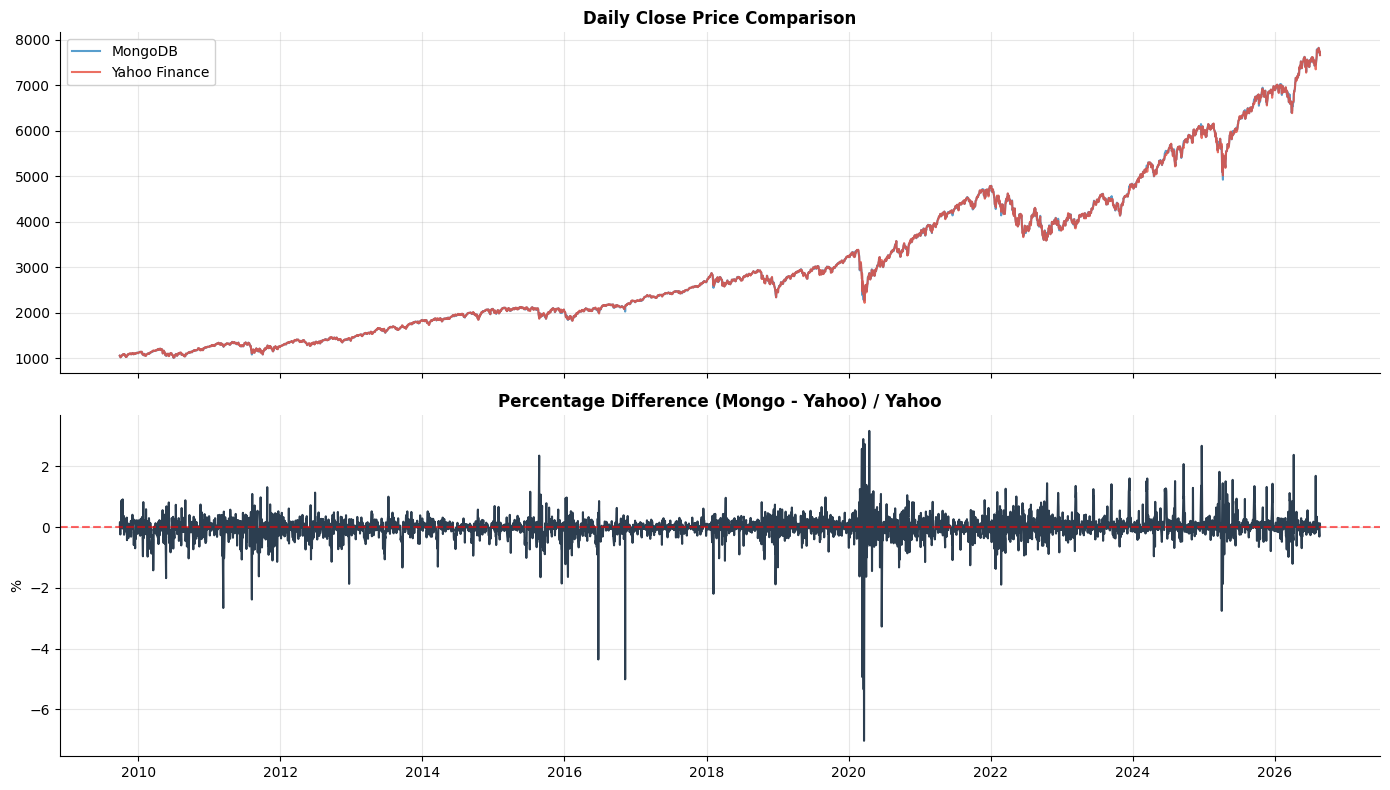

Mean difference: -0.0100%


In [3]:
df_daily = df_raw.resample('D').agg({
    'open': 'first',
    'high': 'max',
    'low': 'min',
    'close': 'last',
    'volume': 'sum'
}).dropna()

es_yahoo = yf.download('ES=F', start=df_daily.index.min(), end=df_daily.index.max(), progress=False)
es_yahoo = es_yahoo[['Open', 'High', 'Low', 'Close', 'Volume']]
es_yahoo.columns = ['open', 'high', 'low', 'close', 'volume']

common_idx = df_daily.index.intersection(es_yahoo.index)
df_daily_aligned = df_daily.loc[common_idx]
es_yahoo_aligned = es_yahoo.loc[common_idx]

comparison = pd.DataFrame({
    'Mongo_close': df_daily_aligned['close'],
    'Yahoo_close': es_yahoo_aligned['close']
})
comparison['diff_pct'] = (comparison['Mongo_close'] - comparison['Yahoo_close']) / comparison['Yahoo_close'] * 100

print("Comparison with Yahoo Finance (daily closes):")
print(comparison.describe())

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
ax1.plot(comparison.index, comparison['Mongo_close'], label='MongoDB', color='#2E86C1', alpha=0.8)
ax1.plot(comparison.index, comparison['Yahoo_close'], label='Yahoo Finance', color='#E74C3C', alpha=0.8)
ax1.set_title('Daily Close Price Comparison', fontweight='bold')
ax1.legend(frameon=True, framealpha=0.9)
ax1.grid(True, alpha=0.3)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

ax2.plot(comparison.index, comparison['diff_pct'], color='#2C3E50', linewidth=1.5)
ax2.axhline(y=0, color='red', linestyle='--', alpha=0.6)
ax2.set_title('Percentage Difference (Mongo - Yahoo) / Yahoo', fontweight='bold')
ax2.set_ylabel('%')
ax2.grid(True, alpha=0.3)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

mean_diff = comparison['diff_pct'].mean()
print(f"Mean difference: {mean_diff:.4f}%")

## RESAMPLE TO MULTIPLE TIMEFRAMES

In [4]:
timeframes = resample_timeframes(df_raw)

print("Timeframes created:")
for name, df in timeframes.items():
    print(f"{name}: {len(df)}")

Timeframes created:
15min: 397663
1H: 101136
4H: 27001
1D: 5258


## ROLL DIAGNOSTIC — outliers vs ES expiration calendar

In [5]:

# --- 1. Isolate days with significant Mongo vs Yahoo discrepancy ---
THRESHOLD_PCT = 1.0  # adjust to be more/less strict

outliers = comparison[comparison['diff_pct'].abs() > THRESHOLD_PCT].copy()
outliers = outliers.sort_values('diff_pct')

print(f"Days with |diff_pct| > {THRESHOLD_PCT}%: {len(outliers)}")
print(outliers[['Mongo_close', 'Yahoo_close', 'diff_pct']])

# --- 2. Generate approximate ES roll calendar (H, M, U, Z contracts) ---
expiry_months = [3, 6, 9, 12]  # March, June, September, December
years = range(df_daily.index.min().year, df_daily.index.max().year + 2)

third_fridays = []
for y in years:
    for m in expiry_months:
        fridays = pd.date_range(f'{y}-{m}-01', f'{y}-{m}-28', freq='W-FRI')
        if len(fridays) >= 3:
            third_fridays.append(fridays[2])

roll_dates = pd.Series(sorted(third_fridays))
ROLL_WINDOW_DAYS = 10  # business days before expiry when the roll typically happens

# --- 3. Cross-check each outlier against the nearest roll window ---
def nearest_roll_distance(date):
    diffs = (roll_dates - date).dt.days
    # we care about the window [-ROLL_WINDOW_DAYS, 0] before expiry
    candidates = diffs[(diffs >= 0) & (diffs <= ROLL_WINDOW_DAYS)]
    return candidates.min() if len(candidates) > 0 else None

outliers['days_to_next_expiry'] = [nearest_roll_distance(d) for d in outliers.index]
outliers['is_roll_window'] = outliers['days_to_next_expiry'].notna()

print("\nOutliers cross-checked against roll calendar:")
print(outliers[['diff_pct', 'days_to_next_expiry', 'is_roll_window']])

pct_explained = outliers['is_roll_window'].mean() * 100
print(f"\n% of outliers explained by roll window: {pct_explained:.1f}%")

# --- 4. Roll flag applied to the FULL daily index (not just outliers) ---
# we'll reuse this later to exclude/flag days in the gap% calculation
df_daily['is_roll_window'] = [
    nearest_roll_distance(d) is not None for d in df_daily.index
]
print(f"\nTotal days flagged as roll window in the full series: {df_daily['is_roll_window'].sum()}")

Days with |diff_pct| > 1.0%: 128
            Mongo_close  Yahoo_close  diff_pct
2020-03-20      2266.50  2437.979980 -7.033691
2020-03-18      2285.00  2414.000000 -5.343828
2016-11-08      2028.50  2135.500000 -5.010536
2020-03-11      2605.00  2740.250000 -4.935681
2016-06-23      2014.00  2105.750000 -4.357117
...                 ...          ...       ...
2020-03-09      2818.50  2747.750000  2.574834
2024-12-20      5996.50  5840.259766  2.675227
2020-03-23      2281.25  2220.500000  2.735870
2020-03-16      2486.25  2416.250000  2.897051
2020-04-16      2875.75  2787.500000  3.165919

[128 rows x 3 columns]

Outliers cross-checked against roll calendar:
            diff_pct  days_to_next_expiry  is_roll_window
2020-03-20 -7.033691                  0.0            True
2020-03-18 -5.343828                  2.0            True
2016-11-08 -5.010536                  NaN           False
2020-03-11 -4.935681                  9.0            True
2016-06-23 -4.357117                  NaN 

## SESSION-DATE DIAGNOSTIC — calendar-day vs trading-session boundary

In [6]:

SESSION_START_HOUR = 18

def to_session_date(timestamp):
    if timestamp.hour >= SESSION_START_HOUR:
        return (timestamp + pd.Timedelta(days=1)).normalize()
    return timestamp.normalize()

df_raw_sess = df_raw.copy()
df_raw_sess['session_date'] = [to_session_date(ts) for ts in df_raw_sess.index]

# --- 2. Rebuild daily bars grouped by session_date instead of calendar day ---
df_daily_session = df_raw_sess.groupby('session_date').agg({
    'open': 'first',
    'high': 'max',
    'low': 'min',
    'close': 'last',
    'volume': 'sum'
})
df_daily_session.index.name = 'time'

# --- 3. Re-run the Mongo vs Yahoo comparison using session-based daily bars ---
common_idx_sess = df_daily_session.index.intersection(es_yahoo.index)
df_daily_session_aligned = df_daily_session.loc[common_idx_sess]
es_yahoo_aligned_sess = es_yahoo.loc[common_idx_sess]

comparison_session = pd.DataFrame({
    'Mongo_close': df_daily_session_aligned['close'],
    'Yahoo_close': es_yahoo_aligned_sess['close']
})
comparison_session['diff_pct'] = (
    (comparison_session['Mongo_close'] - comparison_session['Yahoo_close'])
    / comparison_session['Yahoo_close'] * 100
)

print("Comparison using SESSION-DATE daily bars:")
print(comparison_session.describe())

# --- 4. Compare outlier count before vs after the fix ---
outliers_session = comparison_session[comparison_session['diff_pct'].abs() > THRESHOLD_PCT]
print(f"\nDays with |diff_pct| > {THRESHOLD_PCT}% — calendar-day method: {len(outliers)}")
print(f"Days with |diff_pct| > {THRESHOLD_PCT}% — session-date method:  {len(outliers_session)}")

# --- 5. Check specifically whether the previously "unexplained" dates improve ---
unexplained_dates = outliers[~outliers['is_roll_window']].index
check_unexplained = comparison_session.loc[
    comparison_session.index.intersection(unexplained_dates)
]
print("\nPreviously unexplained outliers, re-measured with session-date bars:")
print(check_unexplained[['Mongo_close', 'Yahoo_close', 'diff_pct']])

Comparison using SESSION-DATE daily bars:
       Mongo_close  Yahoo_close     diff_pct
count  4251.000000  4251.000000  4251.000000
mean   3079.748236  3079.304183    -0.008591
std    1690.255743  1688.695594     0.274966
min    1014.250000  1014.250000    -7.033691
25%    1793.625000  1792.625000    -0.060094
50%    2642.500000  2643.000000     0.000000
75%    4182.375000  4185.625000     0.055736
max    7825.250000  7822.500000     2.675227

Days with |diff_pct| > 1.0% — calendar-day method: 128
Days with |diff_pct| > 1.0% — session-date method:  64

Previously unexplained outliers, re-measured with session-date bars:
            Mongo_close  Yahoo_close  diff_pct
2010-05-24      1066.25      1071.00 -0.443511
2011-08-08      1110.50      1111.25 -0.067492
2011-08-10      1122.75      1123.50 -0.066756
2011-10-26      1243.25      1237.50  0.464646
2011-11-22      1183.00      1182.75  0.021137
2012-06-28      1321.00      1322.50 -0.113422
2013-07-10      1656.00      1648.50  0.454

## COMBINED DIAGNOSTIC — roll + session-date, checking what's left

In [7]:

# --- 1. Re-run outlier detection on the session-date comparison ---
outliers_session_full = comparison_session[
    comparison_session['diff_pct'].abs() > THRESHOLD_PCT
].copy()
outliers_session_full = outliers_session_full.sort_values('diff_pct')

# --- 2. Cross-check these against the roll calendar (reuse nearest_roll_distance) ---
outliers_session_full['days_to_next_expiry'] = [
    nearest_roll_distance(d) for d in outliers_session_full.index
]
outliers_session_full['is_roll_window'] = outliers_session_full['days_to_next_expiry'].notna()

pct_explained_combined = outliers_session_full['is_roll_window'].mean() * 100
print(f"Outliers remaining after session-date fix: {len(outliers_session_full)}")
print(f"% of THOSE explained by roll window: {pct_explained_combined:.1f}%")

# --- 3. Isolate what's still unexplained by EITHER fix ---
still_unexplained = outliers_session_full[~outliers_session_full['is_roll_window']]
still_unexplained = still_unexplained.sort_values('diff_pct', key=abs, ascending=False)

print(f"\nStill unexplained after both fixes: {len(still_unexplained)}")
print(still_unexplained[['Mongo_close', 'Yahoo_close', 'diff_pct']])

# --- 4. Flag the worst offenders for manual inspection (likely source-data errors) ---
SEVERE_THRESHOLD = 1.5
severe_unexplained = still_unexplained[still_unexplained['diff_pct'].abs() > SEVERE_THRESHOLD]
print(f"\nSevere unexplained cases (|diff_pct| > {SEVERE_THRESHOLD}%): {len(severe_unexplained)}")
print(severe_unexplained[['Mongo_close', 'Yahoo_close', 'diff_pct']])

Outliers remaining after session-date fix: 64
% of THOSE explained by roll window: 89.1%

Still unexplained after both fixes: 7
            Mongo_close  Yahoo_close  diff_pct
2025-04-02      5584.50      5712.25 -2.236422
2026-06-05      7550.75      7400.50  2.030268
2026-07-29      7463.00      7351.25  1.520150
2020-04-16      2829.75      2787.50  1.515695
2026-08-04      7652.00      7765.50 -1.461593
2020-02-28      2988.00      2951.00  1.253812
2022-02-03      4522.00      4469.00  1.185948

Severe unexplained cases (|diff_pct| > 1.5%): 4
            Mongo_close  Yahoo_close  diff_pct
2025-04-02      5584.50      5712.25 -2.236422
2026-06-05      7550.75      7400.50  2.030268
2026-07-29      7463.00      7351.25  1.520150
2020-04-16      2829.75      2787.50  1.515695


# FINAL CLEAN DAILY SERIES — session-date + roll flag combined

In [8]:

df_raw_clean = df_raw.copy()
df_raw_clean['session_date'] = [to_session_date(ts) for ts in df_raw_clean.index]

df_daily_clean = df_raw_clean.groupby('session_date').agg({
    'open': 'first',
    'high': 'max',
    'low': 'min',
    'close': 'last',
    'volume': 'sum'
})
df_daily_clean.index.name = 'time'

df_daily_clean['is_roll_window'] = [
    nearest_roll_distance(d) is not None for d in df_daily_clean.index
]

SEVERE_UNEXPLAINED_DATES = pd.to_datetime([
    '2025-04-02', '2026-06-05', '2026-07-29', '2020-04-16'
])
df_daily_clean['is_flagged_exception'] = df_daily_clean.index.isin(SEVERE_UNEXPLAINED_DATES)

print(f"Total daily bars: {len(df_daily_clean)}")
print(f"Bars in roll window: {df_daily_clean['is_roll_window'].sum()}")
print(f"Bars flagged as unresolved exceptions: {df_daily_clean['is_flagged_exception'].sum()}")

df_daily_clean.head()

Total daily bars: 4384
Bars in roll window: 604
Bars flagged as unresolved exceptions: 4


,open,high,low,close,volume,is_roll_window,is_flagged_exception
time,,,,,,,
2009-09-28,1042.25,1061.00,1035.75,1059.75,1523262,False,False
2009-09-29,1059.50,1065.75,1053.25,1055.00,1644005,False,False
2009-09-30,1055.00,1063.25,1041.50,1052.25,2866211,False,False
2009-10-01,1052.00,1056.00,1024.50,1026.50,2734371,False,False
2009-10-02,1026.50,1027.00,1012.00,1022.00,2543533,False,False


## GAP% CALCULATION

In [9]:
# --- 1. PRE-CLOSE reference price: last bar at 16:30 ET for each session ---
df_1630 = df_raw[df_raw.index.time == pd.Timestamp('16:30').time()].copy()
df_1630['session_date'] = [to_session_date(ts) for ts in df_1630.index]

close_1630 = df_1630.groupby('session_date')['close'].last()
close_1630.name = 'close_1630'

# --- 2. OPEN reference price: first bar of the session (18:00) ---
open_1800 = df_daily_clean['open']  # already the session open (18:00 bar)

# --- 3. Align: session D's open is compared against D-1's close_1630 ---
gap_df = pd.DataFrame({'open_1800': open_1800})
gap_df['prev_close_1630'] = close_1630.shift(1).reindex(gap_df.index)

gap_df['gap_pct_adj'] = (
    (gap_df['open_1800'] - gap_df['prev_close_1630']) / gap_df['prev_close_1630'] * 100
)

# --- 4. Attach existing flags ---
gap_df['is_roll_window'] = df_daily_clean['is_roll_window']
gap_df['is_flagged_exception'] = df_daily_clean['is_flagged_exception']
gap_df['dow'] = gap_df.index.day_name()

n_before = len(gap_df)
df_gaps_adj = gap_df.dropna(subset=['gap_pct_adj']).copy()
n_dropped = n_before - len(df_gaps_adj)
print(f"Sessions dropped due to missing 16:30 reference bar: {n_dropped}")

roll_gaps_adj = df_gaps_adj[df_gaps_adj['is_roll_window']]['gap_pct_adj']
normal_gaps_adj = df_gaps_adj[~df_gaps_adj['is_roll_window']]['gap_pct_adj']

print("\nADJUSTED GAP% (16:30 -> 18:00) — NORMAL DAYS")
print(normal_gaps_adj.describe())
print(f"Mean |gap| adjusted: {normal_gaps_adj.abs().mean():.4f}%")

# --- 5. Comparison against old gap — guarded, in case 'normal_gaps' isn't
# defined in this kernel session (e.g. kernel was restarted) ---
if 'normal_gaps' in dir():
    print("\nQuick comparison against the old gap (17:45->18:00):")
    print(f"  Old      — std: {normal_gaps.std():.4f}%, mean|gap|: {normal_gaps.abs().mean():.4f}%")
    print(f"  Adjusted — std: {normal_gaps_adj.std():.4f}%, mean|gap|: {normal_gaps_adj.abs().mean():.4f}%")
else:
    print("\n[skip] 'normal_gaps' not in scope — run the original gap_pct cell first if you want the old-vs-new comparison.")

# --- 6. Diagnostic: which sessions are missing the 16:30 bar? ---
dropped_sessions = gap_df[gap_df['gap_pct_adj'].isna()].index
print(f"\nExamples of sessions without a 16:30 bar ({len(dropped_sessions)} total):")
print(dropped_sessions[:20])

print("\nDropped sessions by year:")
print(dropped_sessions.year.value_counts().sort_index())

Sessions dropped due to missing 16:30 reference bar: 325

ADJUSTED GAP% (16:30 -> 18:00) — NORMAL DAYS
count    3483.000000
mean       -0.011423
std         0.309776
min        -3.601359
25%        -0.039926
50%         0.000000
75%         0.036824
max         2.877153
Name: gap_pct_adj, dtype: float64
Mean |gap| adjusted: 0.1211%

[skip] 'normal_gaps' not in scope — run the original gap_pct cell first if you want the old-vs-new comparison.

Examples of sessions without a 16:30 bar (325 total):
DatetimeIndex(['2009-09-28', '2009-10-02', '2009-10-09', '2009-10-16',
               '2009-10-23', '2009-10-30', '2009-11-06', '2009-11-13',
               '2009-11-20', '2009-11-26', '2009-11-27', '2009-12-04',
               '2009-12-11', '2009-12-18', '2009-12-24', '2009-12-31',
               '2010-01-08', '2010-01-15', '2010-01-18', '2010-01-22'],
              dtype='datetime64[us]', name='time', freq=None)

Dropped sessions by year:
time
2009    16
2010    58
2011    58
2012    56
2013 

## GAP% DISTRIBUTION — descriptive statistics

ADJUSTED GAP% DISTRIBUTION (16:30 -> 18:00)
count    3483.000000
mean       -0.011423
std         0.309776
min        -3.601359
25%        -0.039926
50%         0.000000
75%         0.036824
max         2.877153
Name: gap_pct_adj, dtype: float64
Mean |gap|: 0.1211%
Skew: -2.1900
Excess kurtosis: 35.3454

Up gaps: 1571 (45.1%), mean 0.1216%
Down gaps: 1649 (47.3%), mean -0.1400%

  percentile  abs_gap_pct
         50     0.038395
         75     0.091228
         90     0.266292
         95     0.522060
         99     1.559202


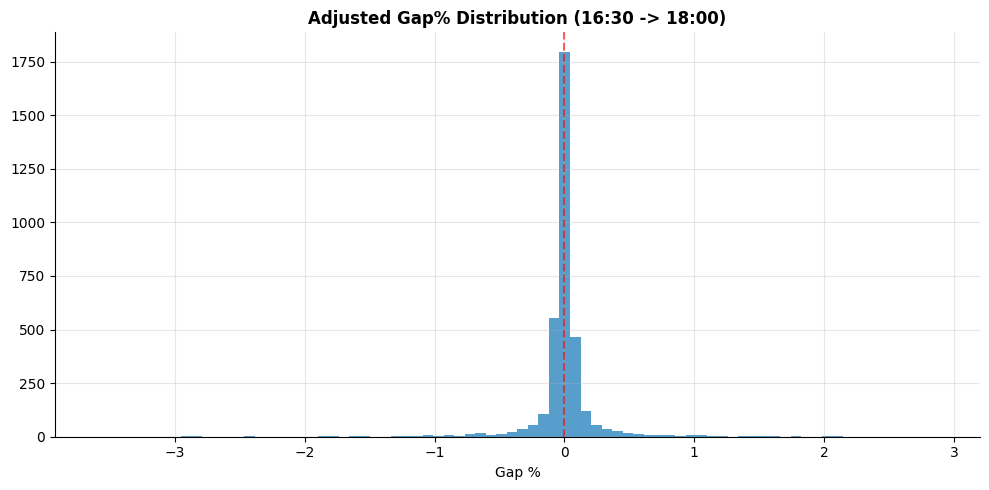

In [10]:
# --- Gap size distribution — descriptive only ---
print("ADJUSTED GAP% DISTRIBUTION (16:30 -> 18:00)")
print(normal_gaps_adj.describe())
print(f"Mean |gap|: {normal_gaps_adj.abs().mean():.4f}%")
print(f"Skew: {normal_gaps_adj.skew():.4f}")
print(f"Excess kurtosis: {normal_gaps_adj.kurt():.4f}")

# Direction split — how often gaps are up vs down, and by how much
up_gaps = normal_gaps_adj[normal_gaps_adj > 0]
down_gaps = normal_gaps_adj[normal_gaps_adj < 0]
print(f"\nUp gaps: {len(up_gaps)} ({len(up_gaps)/len(normal_gaps_adj)*100:.1f}%), mean {up_gaps.mean():.4f}%")
print(f"Down gaps: {len(down_gaps)} ({len(down_gaps)/len(normal_gaps_adj)*100:.1f}%), mean {down_gaps.mean():.4f}%")

# Percentile table — where the mass of the distribution sits
percentiles = [50, 75, 90, 95, 99]
pct_table = pd.DataFrame({
    'percentile': percentiles,
    'abs_gap_pct': [normal_gaps_adj.abs().quantile(p/100) for p in percentiles]
})
print("\n", pct_table.to_string(index=False))

# Optional: quick histogram, same visual style as the rest of the notebook
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(normal_gaps_adj, bins=80, color='#2E86C1', alpha=0.8)
ax.axvline(0, color='red', linestyle='--', alpha=0.6)
ax.set_title('Adjusted Gap% Distribution (16:30 -> 18:00)', fontweight='bold')
ax.set_xlabel('Gap %')
ax.grid(True, alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.show()

## GAP% SEASONALITY — day of week

Gap by day of week:
               mean       std  count
dow                                 
Monday    -0.032923  0.626642  793.0
Tuesday    0.002699  0.249990  871.0
Wednesday -0.002890  0.161118  867.0
Thursday  -0.014053  0.128006  848.0
Friday     0.000738  0.148225  680.0
Sunday          NaN       NaN    NaN

No sessions flagged as Sunday — check to_session_date() logic


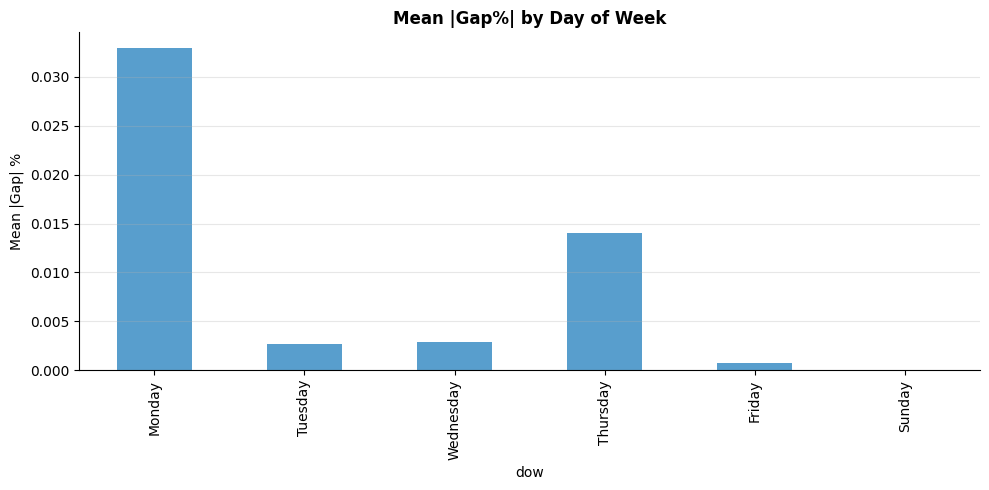

In [11]:
gap_by_dow = df_gaps_adj.groupby('dow')['gap_pct_adj'].agg(['mean', 'std', 'count'])
gap_by_dow = gap_by_dow.reindex(['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Sunday'])
print("Gap by day of week:")
print(gap_by_dow)

if 'Sunday' in df_gaps_adj['dow'].values:
    print("\nWeekend gap (Sunday reopen):")
    print(df_gaps_adj[df_gaps_adj['dow'] == 'Sunday']['gap_pct_adj'].describe())
else:
    print("\nNo sessions flagged as Sunday — check to_session_date() logic")

fig, ax = plt.subplots(figsize=(10, 5))
gap_by_dow['mean'].abs().plot(kind='bar', ax=ax, color='#2E86C1', alpha=0.8)
ax.set_title('Mean |Gap%| by Day of Week', fontweight='bold')
ax.set_ylabel('Mean |Gap| %')
ax.grid(True, alpha=0.3, axis='y')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.show()

## DATA COMPLETENESS CHECK: BARS PER SESSION

In [12]:
# --- Data completeness check: bars per session by year ---
session_dates = [to_session_date(ts) for ts in df_raw.index]
bars_per_session = pd.Series(session_dates).value_counts().sort_index()
bars_per_session = bars_per_session.to_frame('n_bars')
bars_per_session['year'] = bars_per_session.index.year

# A full 18:00->17:45 session should have ~94-95 bars of 15min (23.75h)
print("Bars per session — summary by year:")
print(bars_per_session.groupby('year')['n_bars'].describe())

# Flag sessions with meaningfully fewer bars than expected
EXPECTED_BARS = 90  # conservative floor; adjust after seeing the describe() above
incomplete = bars_per_session[bars_per_session['n_bars'] < EXPECTED_BARS]
print(f"\nSessions with < {EXPECTED_BARS} bars: {len(incomplete)}")
print(incomplete.groupby('year').size())

Bars per session — summary by year:
      count       mean        std   min   25%   50%   75%   max
year                                                           
2009   68.0  91.676471   3.971695  70.0  93.0  93.0  93.0  95.0
2010  259.0  91.648649   4.297569  61.0  93.0  93.0  93.0  95.0
2011  258.0  91.550388   4.828517  45.0  93.0  93.0  93.0  94.0
2012  259.0  90.965251   6.591834  44.0  92.0  93.0  93.0  94.0
2013  258.0  90.972868   5.552302  44.0  92.0  92.0  92.0  93.0
2014  259.0  90.868726   6.998210   4.0  92.0  92.0  92.0  93.0
2015  259.0  91.150579   3.334764  62.0  91.0  92.0  92.0  93.0
2016  258.0  90.612403   2.424936  76.0  91.0  91.0  91.0  92.0
2017  257.0  90.564202   2.576328  76.0  91.0  91.0  91.0  92.0
2018  258.0  90.399225   3.221933  62.0  91.0  91.0  91.0  92.0
2019  258.0  90.449612   2.793715  76.0  91.0  91.0  91.0  92.0
2020  260.0  90.188462   6.113396   1.0  91.0  91.0  91.0  91.0
2021  259.0  90.984556   3.159787  61.0  91.0  92.0  92.0  92.0
2022

## DATA COMPLETENESS — recalibrated threshold, isolating genuine gap

In [13]:
# Recalibrate: most 'normal' sessions cluster at 91-93 bars (daily maintenance
# break accounts for ~2-4 missing bars). A session with drastically fewer bars
# (holidays give partial data, not near-zero) is the real signal.
LOWER_THRESHOLD = 80

truly_broken = bars_per_session[bars_per_session['n_bars'] < LOWER_THRESHOLD]
print(f"Sessions with < {LOWER_THRESHOLD} bars (likely genuine data gaps): {len(truly_broken)}")
print(truly_broken.groupby('year').size())
print("\nWorst offenders:")
print(truly_broken.sort_values('n_bars').head(20))

Sessions with < 80 bars (likely genuine data gaps): 187
year
2009     3
2010     8
2011     8
2012    13
2013    11
2014    12
2015     9
2016     7
2017     8
2018    10
2019    10
2020     9
2021     8
2022     8
2023    11
2024    10
2025    11
2026    31
dtype: int64

Worst offenders:
            n_bars  year
2020-02-23       1  2020
2023-11-05       1  2023
2026-07-05       1  2026
2026-06-19       3  2026
2014-03-09       4  2014
2026-07-04      17  2026
2026-07-25      33  2026
2026-05-02      33  2026
2026-05-09      33  2026
2026-05-16      33  2026
2026-05-30      33  2026
2026-06-06      33  2026
2026-06-13      33  2026
2026-08-01      33  2026
2026-05-23      33  2026
2026-06-27      33  2026
2026-07-18      33  2026
2026-07-11      33  2026
2025-11-28      34  2025
2014-01-02      44  2014


## WEEKEND VS WEEKDAY GAP — separating Friday->Sunday reopen from intra-week gaps

In [14]:
# --- Separate weekend gap from weekday gaps ---
# "Monday"-labeled sessions actually correspond to Sunday's 18:00 reopen,
# because to_session_date() rolls Sunday hour>=18 into the next calendar day.
df_gaps_adj['prev_session_dow'] = df_gaps_adj.index.to_series().shift(1).dt.day_name()

is_weekend_gap = (df_gaps_adj['dow'] == 'Monday') & (df_gaps_adj['prev_session_dow'] == 'Friday')
df_gaps_adj['gap_type'] = 'weekday'
df_gaps_adj.loc[is_weekend_gap, 'gap_type'] = 'weekend'

print("Weekend gap (Fri close -> Sun 18:00 reopen):")
print(df_gaps_adj[df_gaps_adj['gap_type'] == 'weekend']['gap_pct_adj'].describe())

print("\n'Monday'-labeled sessions that are NOT weekend gaps (holiday-shifted?):")
print(df_gaps_adj[(df_gaps_adj['dow'] == 'Monday') & (~is_weekend_gap)][['gap_pct_adj', 'prev_session_dow']])

print("\nWeekday-only gaps (true intra-week, Tue-Fri):")
weekday_only = df_gaps_adj[df_gaps_adj['gap_type'] == 'weekday']
gap_by_dow_clean = weekday_only.groupby('dow')['gap_pct_adj'].agg(['mean', 'std', 'count'])
print(gap_by_dow_clean.reindex(['Tuesday', 'Wednesday', 'Thursday', 'Friday']))

# --- Correction: extend the weekend/holiday flag to any gap where 1+ extra
# session was skipped (previous session wasn't literally the immediate prior
# calendar day) — catches Thanksgiving, July 4th, Christmas, Good Friday etc.
df_gaps_adj['days_since_prev_session'] = (
    df_gaps_adj.index.to_series() - df_gaps_adj.index.to_series().shift(1)
).dt.days

is_extended_gap = (df_gaps_adj['dow'] == 'Monday') & (df_gaps_adj['prev_session_dow'] != 'Friday')
df_gaps_adj.loc[is_extended_gap, 'gap_type'] = 'holiday_extended'

print(f"\nHoliday-extended gaps (Friday session missing, or more): {is_extended_gap.sum()}")
print(df_gaps_adj[is_extended_gap][['gap_pct_adj', 'prev_session_dow', 'days_since_prev_session']].describe())

# Re-run the clean weekday-only table, now properly excluding weekend AND holiday-extended
weekday_only_clean = df_gaps_adj[df_gaps_adj['gap_type'] == 'weekday']
print("\nCorrected weekday-only gap stats (true Tue-Fri, no contamination):")
print(weekday_only_clean.groupby('dow')['gap_pct_adj'].agg(['mean', 'std', 'count']).reindex(['Tuesday', 'Wednesday', 'Thursday', 'Friday']))

Weekend gap (Fri close -> Sun 18:00 reopen):
count    608.000000
mean      -0.029851
std        0.404798
min       -3.066767
25%       -0.075543
50%        0.000000
75%        0.088006
max        1.452848
Name: gap_pct_adj, dtype: float64

'Monday'-labeled sessions that are NOT weekend gaps (holiday-shifted?):
            gap_pct_adj prev_session_dow
time                                    
2009-10-05    -0.486973         Thursday
2009-10-12     0.352444         Thursday
2009-10-19    -1.008018         Thursday
2009-10-26    -1.306441         Thursday
2009-11-02    -2.849741         Thursday
...                 ...              ...
2025-04-21    -0.686058         Thursday
2025-07-07     0.493886        Wednesday
2025-12-01     0.377068        Wednesday
2026-04-06    -0.502019         Thursday
2026-06-22     1.011014         Thursday

[185 rows x 2 columns]

Weekday-only gaps (true intra-week, Tue-Fri):
               mean       std  count
dow                                 
Tuesday   

## GAP EXTREME EVENTS — largest gaps and cross-check against flagged exceptions

In [15]:
# --- Extreme gap events — same treatment as the timeframe EDA sections ---
top_up = normal_gaps_adj.sort_values(ascending=False).head(10)
top_down = normal_gaps_adj.sort_values(ascending=True).head(10)

print("Top 10 up gaps:")
print(top_up)
print("\nTop 10 down gaps:")
print(top_down)

# Cross-check: are any of these driven by the still-unresolved flagged exceptions?
flagged_dates = set(df_daily_clean[df_daily_clean['is_flagged_exception']].index)
overlap = (set(top_up.index) | set(top_down.index)) & flagged_dates
print(f"\nFlagged exception dates overlapping top gaps: {overlap}")

Top 10 up gaps:
time
2012-07-02    2.877153
2011-11-14    2.140982
2012-08-06    2.111642
2010-09-27    2.074504
2010-05-24    1.996711
2010-08-30    1.988024
2020-04-17    1.931464
2012-07-30    1.789668
2011-10-17    1.754020
2011-10-24    1.632231
Name: gap_pct_adj, dtype: float64

Top 10 down gaps:
time
2010-06-07   -3.601359
2020-03-02   -3.066767
2011-10-03   -2.938634
2018-12-26   -2.934491
2009-11-02   -2.849741
2010-07-19   -2.836879
2026-06-08   -2.642706
2011-08-08   -2.485380
2012-06-04   -2.429692
2012-05-07   -2.396828
Name: gap_pct_adj, dtype: float64

Flagged exception dates overlapping top gaps: set()


## EXTREME GAPS — cross-check against session data completeness

In [16]:
top_up_dates = normal_gaps_adj.sort_values(ascending=False).head(10).index
top_down_dates = normal_gaps_adj.sort_values(ascending=True).head(10).index
all_top = top_up_dates.append(top_down_dates)

print("Year distribution of top-20 extreme gaps:")
print(all_top.year.value_counts().sort_index())

print("\nBar count on those specific extreme-gap sessions (checking for stale/thin reference data):")
print(bars_per_session.loc[bars_per_session.index.intersection(all_top)].sort_values('n_bars'))

Year distribution of top-20 extreme gaps:
time
2009    1
2010    5
2011    5
2012    5
2018    1
2020    2
2026    1
Name: count, dtype: int64

Bar count on those specific extreme-gap sessions (checking for stale/thin reference data):
            n_bars  year
2026-06-08      60  2026
2020-03-02      91  2020
2018-12-26      91  2018
2020-04-17      91  2020
2012-08-06      93  2012
2012-07-30      93  2012
2012-07-02      93  2012
2012-06-04      93  2012
2012-05-07      93  2012
2011-11-14      93  2011
2009-11-02      93  2009
2011-10-03      93  2011
2011-08-08      93  2011
2010-08-30      93  2010
2010-06-07      93  2010
2010-05-24      93  2010
2011-10-17      93  2011
2011-10-24      93  2011
2010-09-27      94  2010
2010-07-19      94  2010


## LIQUIDITY AROUND REOPEN — volume in first bars after 18:00

In [17]:
# --- Volume profile: first bars after 18:00 reopen vs rest of session ---
df_raw_hour = df_raw.copy()
df_raw_hour['time_of_day'] = df_raw_hour.index.time
df_raw_hour['session_date'] = [to_session_date(ts) for ts in df_raw_hour.index]

# first 30 minutes after reopen = bars at 18:00 and 18:15
reopen_mask = df_raw_hour['time_of_day'].isin([
    pd.Timestamp('18:00').time(), pd.Timestamp('18:15').time()
])

reopen_vol = df_raw_hour[reopen_mask].groupby('session_date')['volume'].mean()
rest_vol = df_raw_hour[~reopen_mask].groupby('session_date')['volume'].mean()

print("Avg volume — first 30min after 18:00 reopen:")
print(reopen_vol.describe())
print("\nAvg volume — rest of session:")
print(rest_vol.describe())
print(f"\nReopen volume as % of rest-of-session average: "
      f"{(reopen_vol.mean() / rest_vol.mean() * 100):.1f}%")

Avg volume — first 30min after 18:00 reopen:
count     4358.000000
mean      3163.584442
std       3714.727056
min         34.500000
25%       1367.250000
50%       2037.750000
75%       3357.375000
max      53584.000000
Name: volume, dtype: float64

Avg volume — rest of session:
count     4384.000000
mean     17474.310606
std       7313.371286
min          1.000000
25%      13091.347815
50%      16678.573783
75%      21004.143413
max      70313.287356
Name: volume, dtype: float64

Reopen volume as % of rest-of-session average: 18.1%


## RUN DETAILED EDA ON EACH TIMEFRAME


ANALYZING 15MIN TIMEFRAME

COMPLETE ANALYSIS: 15min
Bars: 397663
Period: 2009-09-27 18:00:00 → 2026-08-21 16:45:00

SHORT-TERM BEHAVIOR          LONG-TERM DRIFT (TREND)
RANDOM WALK
Hurst 0.50
BULLISH
~12.5%/year (mean return)

DISTRIBUTION
TAILS?
Mean return: 0.00%
Annualized volatility: 15.4%
Skewness: -0.22 (left tail)
Excess Kurtosis: 83.75 (fat tails)
Normality: NOT normal
Extreme days (>3σ): 6838 (1.7%)


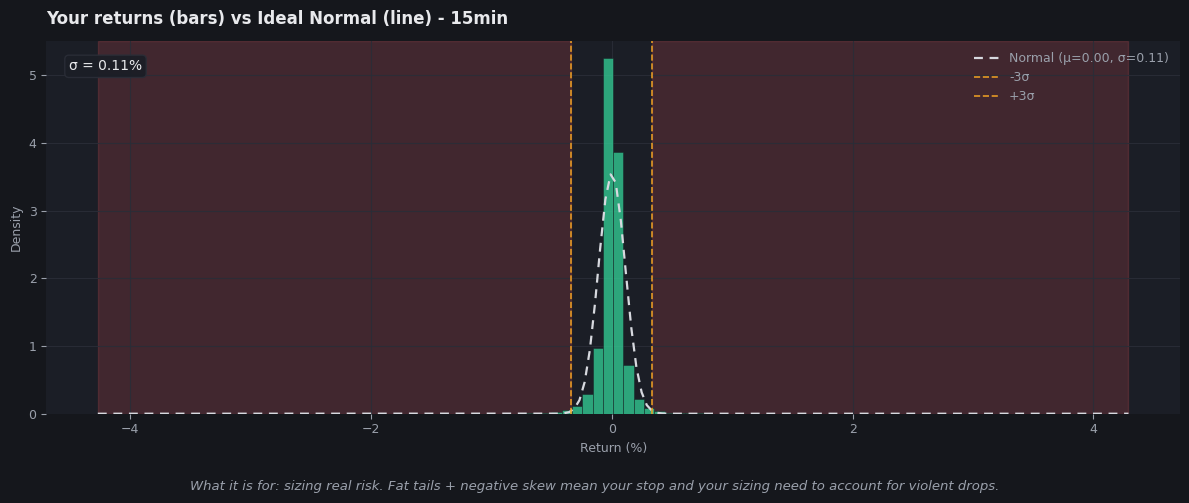


VOLATILITY
REGIMES?
Recent vs Mean vol: 0.45x
Recent volatility (daily): 0.05%
Historical volatility (daily): 0.11%
Comes in waves? low


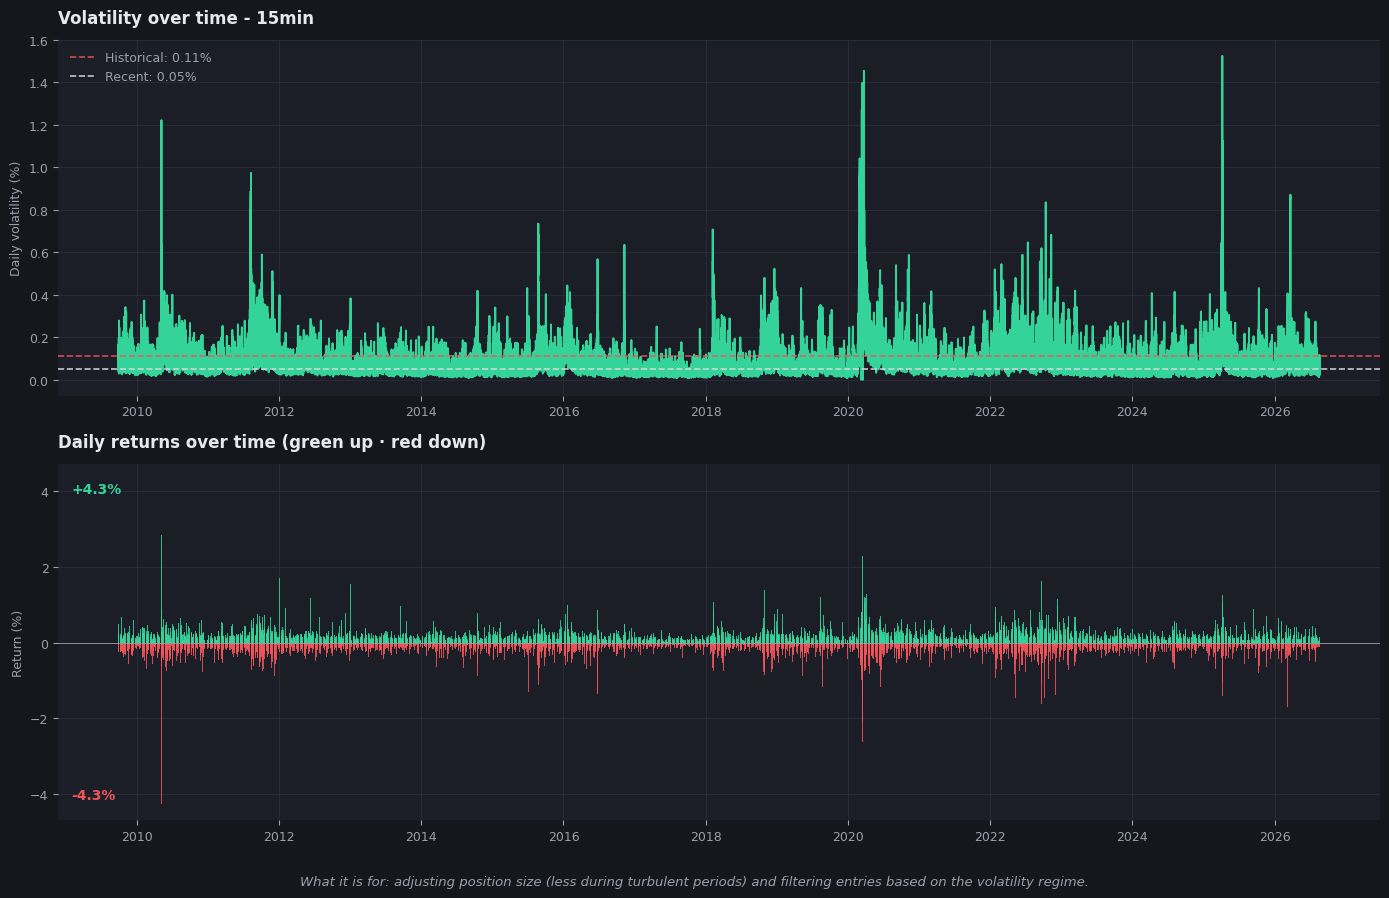


AUTOCORRELATION · MEMORY
PERSISTENCE?
Lag 1 · vs yesterday: -0.01 reverts
Lag 5 · vs 5 days ago: -0.01 reverts
Lag 20 · vs 20 days ago: -0.01 reverts


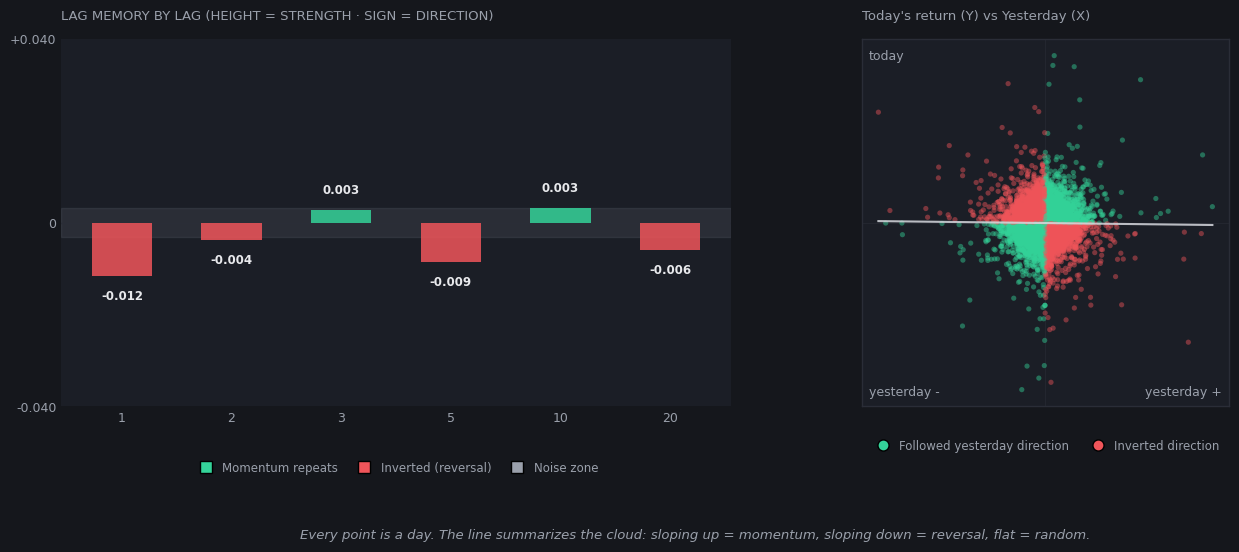


PATTERNS
SEASONALITY?


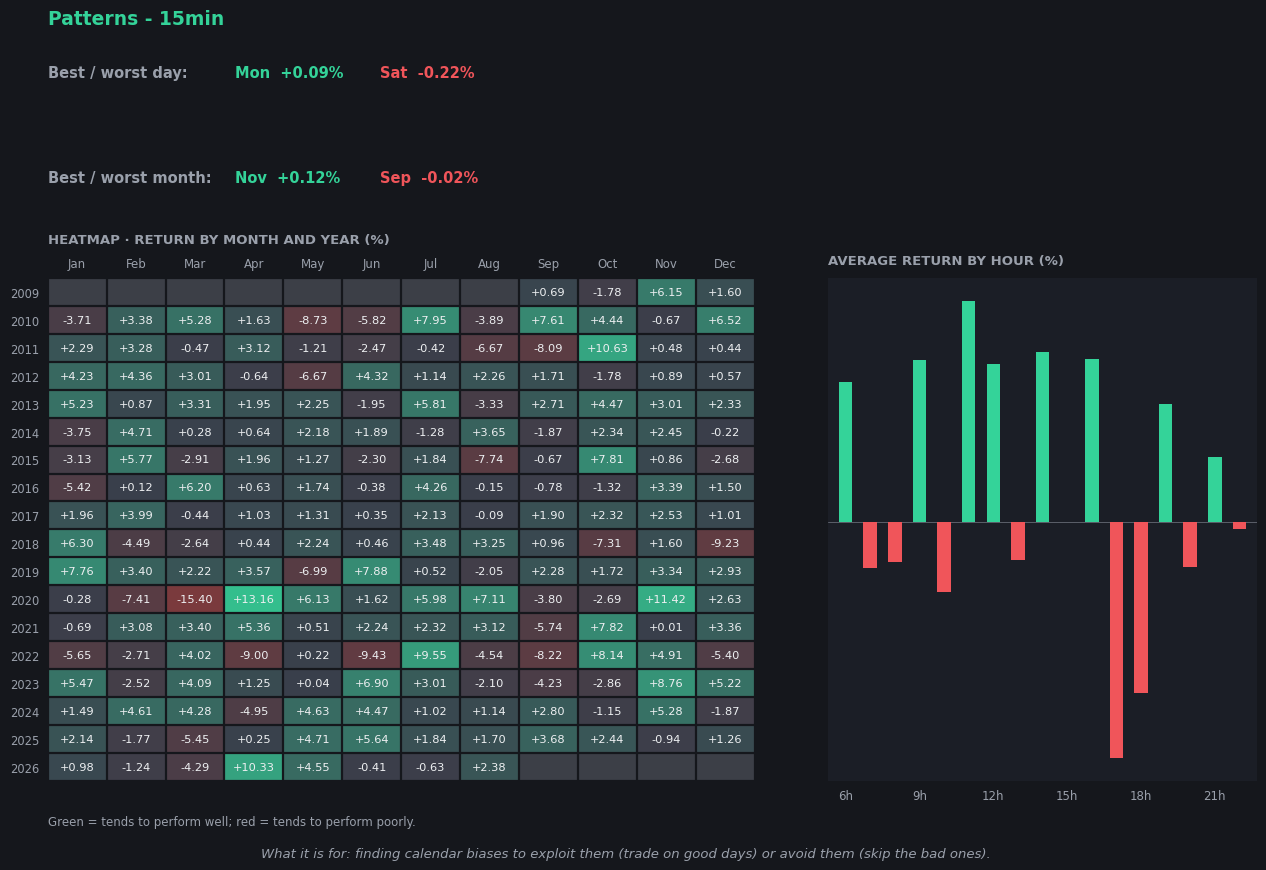


Average return by day of week (Mon-Fri, %):
Mon: 0.09%
Tue: 0.06%
Wed: 0.05%
Thu: 0.02%
Fri: 0.03%

Average return by month (%):
Jan: 0.03%
Feb: 0.04%
Mar: 0.01%
Apr: 0.07%
May: 0.02%
Jun: 0.03%
Jul: 0.11%
Aug: -0.01%
Sep: -0.02%
Oct: 0.07%
Nov: 0.12%
Dec: 0.02%

Average return by hour (6:00-22:00, %):
06:00: 0.00%
07:00: -0.00%
08:00: -0.00%
09:00: 0.00%
10:00: -0.00%
11:00: 0.00%
12:00: 0.00%
13:00: -0.00%
14:00: 0.00%
15:00: -0.00%
16:00: 0.00%
17:00: -0.00%
18:00: -0.00%
19:00: 0.00%
20:00: -0.00%
21:00: 0.00%
22:00: -0.00%

EXTREME EVENTS
REACTION?


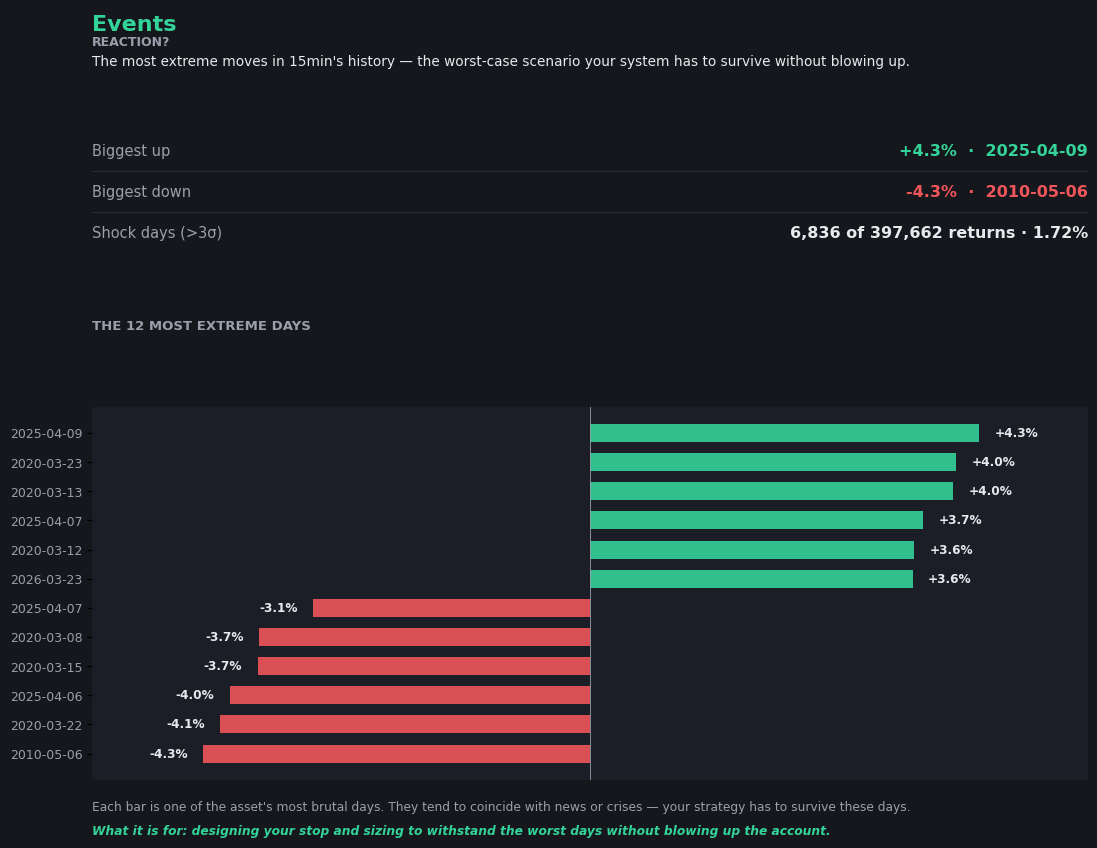

Biggest up: +4.3%
Biggest down: -4.3%
Shock days (>3σ): 6838 of 397,662 returns · 1.72%

Top 12 up days:
+4.3% - 2025-04-09
+4.0% - 2020-03-23
+4.0% - 2020-03-13
+3.7% - 2025-04-07
+3.6% - 2020-03-12
+3.6% - 2026-03-23

Top 12 down days:
-4.3% - 2010-05-06
-4.1% - 2020-03-22
-4.0% - 2025-04-06
-3.7% - 2020-03-15
-3.7% - 2020-03-08
-3.1% - 2025-04-07

FROM BEHAVIOR TO SYSTEM
Mean reversion: 50%
Trending: 50%

This asset is more likely MIXED (MR: 50%, Trend: 50%) → explore a combination of both.

--------------------------------------------------
If the asset shows...	Explore...	In this asset
--------------------------------------------------
Autocorrelation neutral	→ mean reversion	~0%
Volatility regimes	→ volatility expansion	low
Seasonal patterns	→ seasonal systems	high
Response to events	→ event-driven	medium


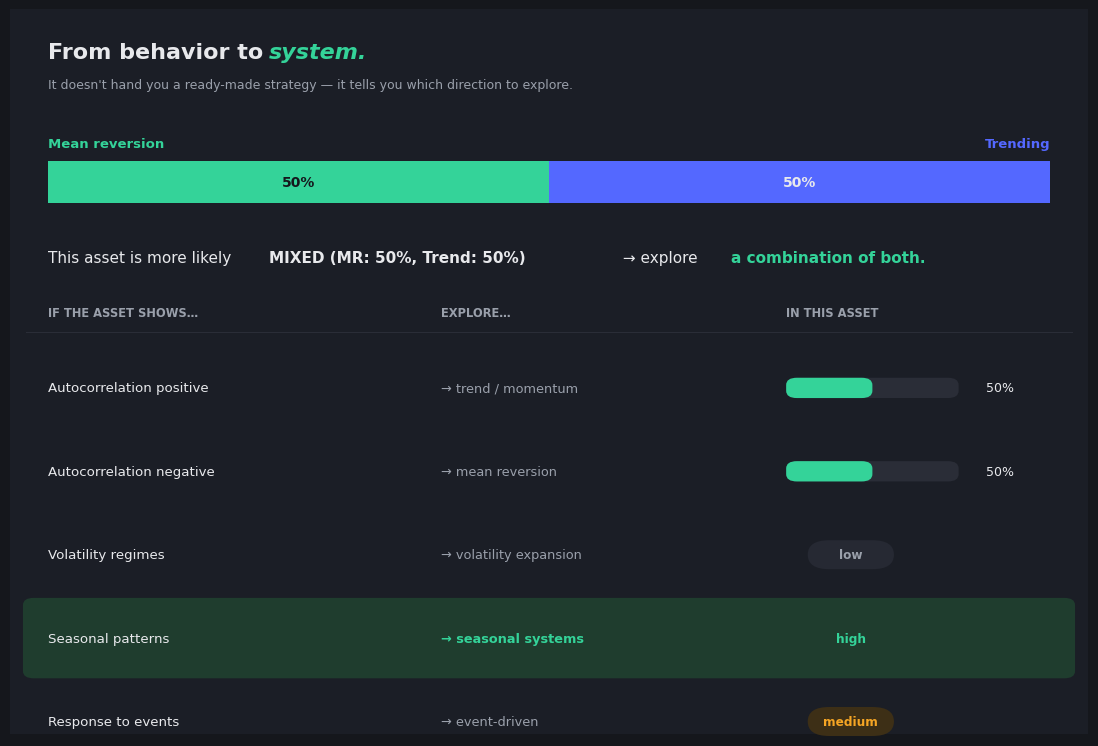


GLOSSARY
WHAT EACH NUMBER MEANS

Mean Return
How much it goes up or down on average per period. If positive, the price has an upward drift (long-term trend).
→ 0.00%

Annualized Volatility
How much the price swings, annualized. Used to compare risk across different assets.
→ 15.4%

Skewness
Which side the surprises lean toward. Negative means down moves are more violent than up moves.
→ -0.22 (left tail)

Excess Kurtosis
How frequent extreme events are. High = more shocks than a normal distribution would predict.
→ 83.75 (fat tails)

Normality (Jarque-Bera)
Test if returns follow a normal distribution. In markets, they almost never do.
→ NOT normal

Autocorrelation
Whether today's return resembles yesterday's. Negative means reversal (mean reversion).
→ Lag 1: -0.012

Hurst Exponent
Measures price memory. <0.5 = reverting.
→ 0.499

Volatility Clustering
Calm and turmoil come in waves: a volatile day tends to be followed by another volatile day (ARCH effect).
→ low

Seasonality
Whether

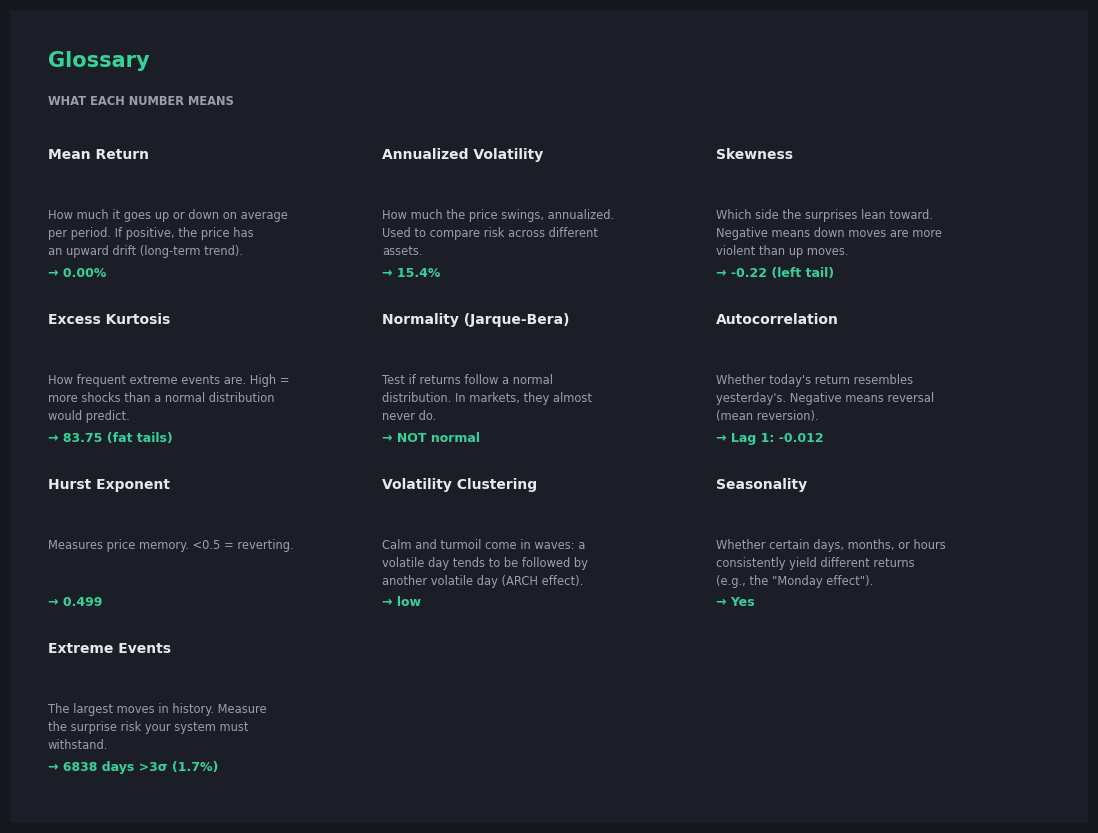




ANALYZING 1H TIMEFRAME

COMPLETE ANALYSIS: 1H
Bars: 101136
Period: 2009-09-27 18:00:00 → 2026-08-21 16:00:00

SHORT-TERM BEHAVIOR          LONG-TERM DRIFT (TREND)
RANDOM WALK
Hurst 0.50
BULLISH
~12.5%/year (mean return)

DISTRIBUTION
TAILS?
Mean return: 0.00%
Annualized volatility: 15.4%
Skewness: 0.11 (right tail)
Excess Kurtosis: 49.53 (fat tails)
Normality: NOT normal
Extreme days (>3σ): 1797 (1.8%)


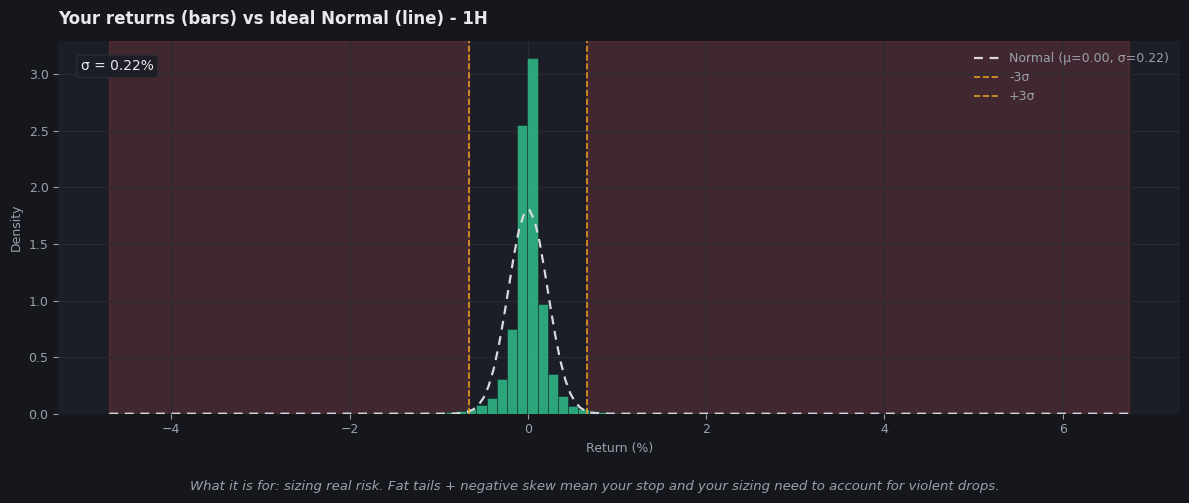


VOLATILITY
REGIMES?
Recent vs Mean vol: 0.47x
Recent volatility (daily): 0.10%
Historical volatility (daily): 0.22%
Comes in waves? low


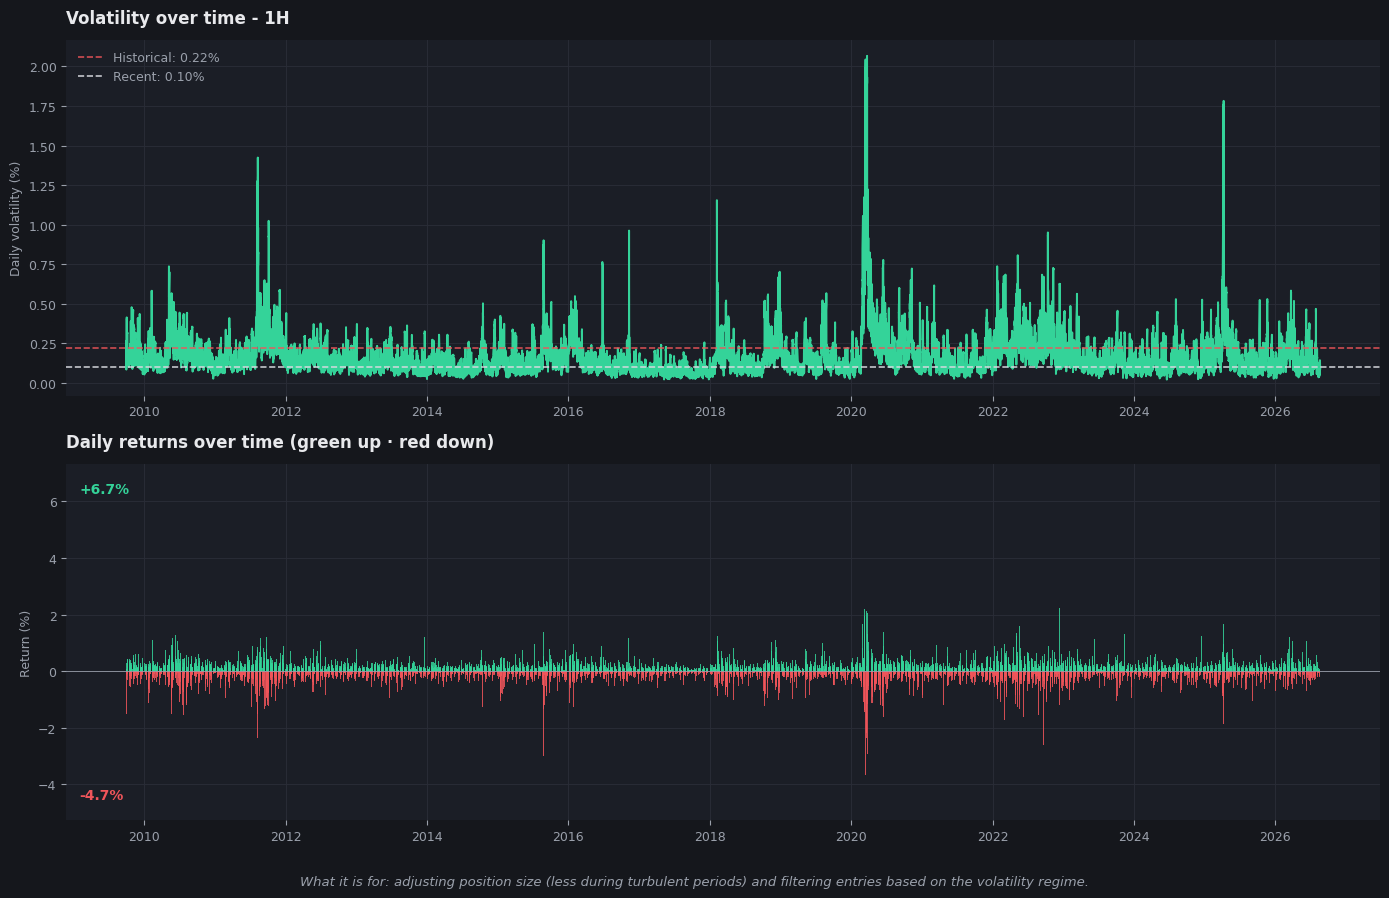


AUTOCORRELATION · MEMORY
PERSISTENCE?
Lag 1 · vs yesterday: -0.01 reverts
Lag 5 · vs 5 days ago: -0.01 reverts
Lag 20 · vs 20 days ago: 0.00 ~0


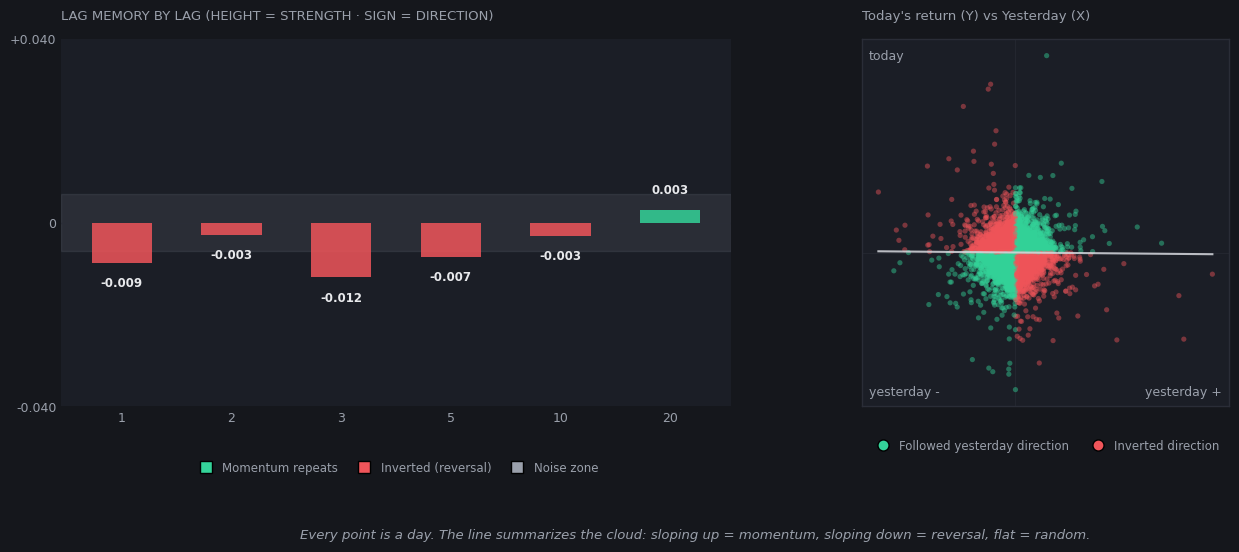


PATTERNS
SEASONALITY?


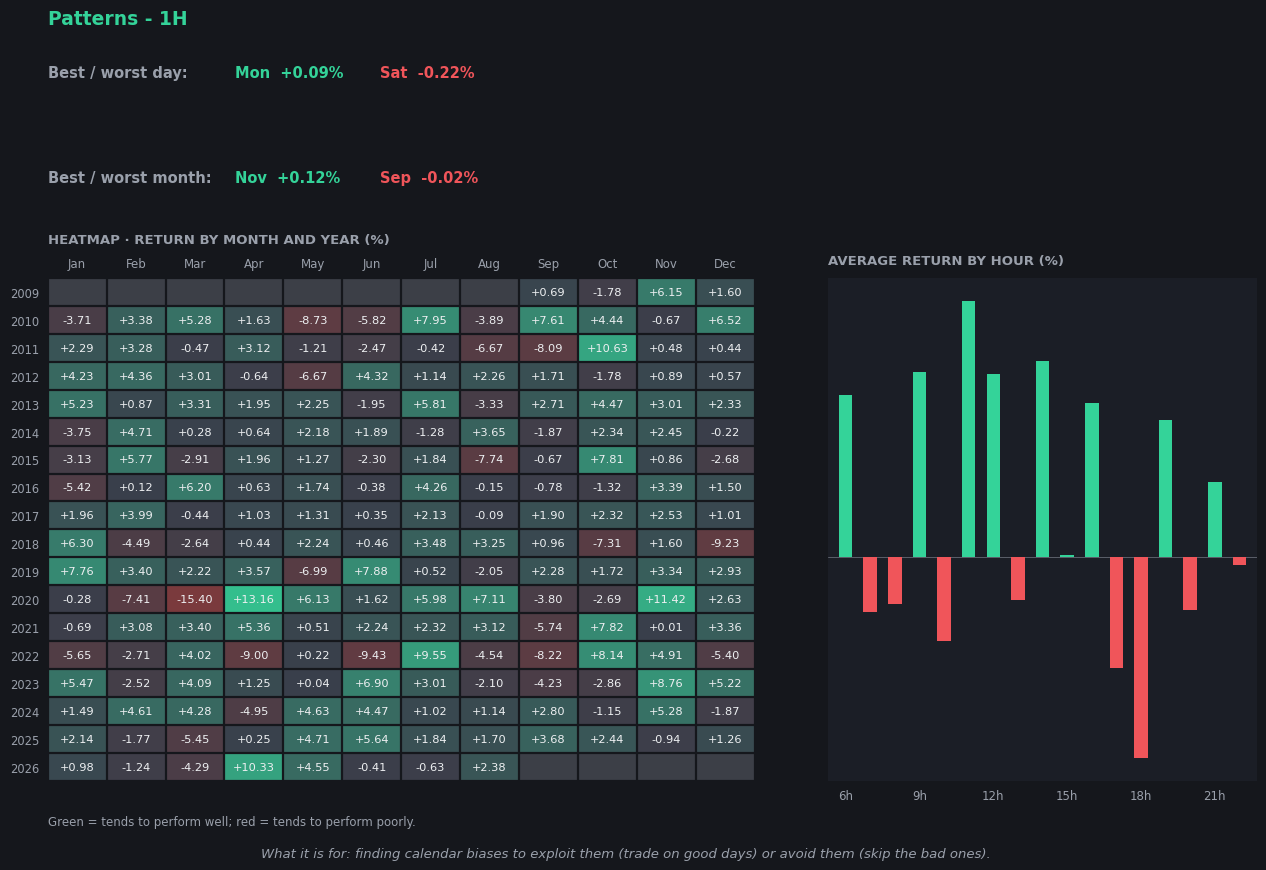


Average return by day of week (Mon-Fri, %):
Mon: 0.09%
Tue: 0.06%
Wed: 0.05%
Thu: 0.02%
Fri: 0.03%

Average return by month (%):
Jan: 0.03%
Feb: 0.04%
Mar: 0.01%
Apr: 0.07%
May: 0.02%
Jun: 0.03%
Jul: 0.11%
Aug: -0.01%
Sep: -0.02%
Oct: 0.07%
Nov: 0.12%
Dec: 0.02%

Average return by hour (6:00-22:00, %):
06:00: 0.00%
07:00: -0.00%
08:00: -0.00%
09:00: 0.01%
10:00: -0.00%
11:00: 0.01%
12:00: 0.01%
13:00: -0.00%
14:00: 0.01%
15:00: 0.00%
16:00: 0.00%
17:00: -0.00%
18:00: -0.01%
19:00: 0.00%
20:00: -0.00%
21:00: 0.00%
22:00: -0.00%

EXTREME EVENTS
REACTION?


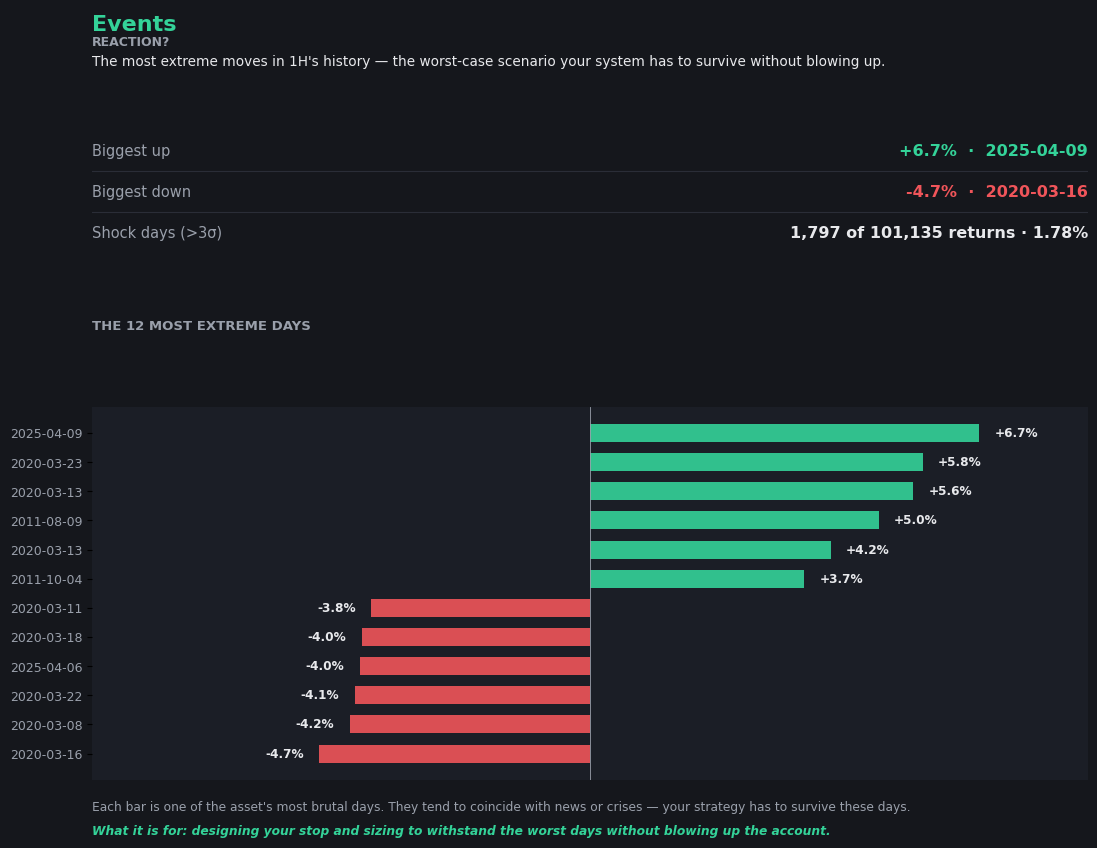

Biggest up: +6.7%
Biggest down: -4.7%
Shock days (>3σ): 1797 of 101,135 returns · 1.78%

Top 12 up days:
+6.7% - 2025-04-09
+5.8% - 2020-03-23
+5.6% - 2020-03-13
+5.0% - 2011-08-09
+4.2% - 2020-03-13
+3.7% - 2011-10-04

Top 12 down days:
-4.7% - 2020-03-16
-4.2% - 2020-03-08
-4.1% - 2020-03-22
-4.0% - 2025-04-06
-4.0% - 2020-03-18
-3.8% - 2020-03-11

FROM BEHAVIOR TO SYSTEM
Mean reversion: 50%
Trending: 50%

This asset is more likely MIXED (MR: 50%, Trend: 50%) → explore a combination of both.

--------------------------------------------------
If the asset shows...	Explore...	In this asset
--------------------------------------------------
Autocorrelation neutral	→ mean reversion	~0%
Volatility regimes	→ volatility expansion	low
Seasonal patterns	→ seasonal systems	high
Response to events	→ event-driven	medium


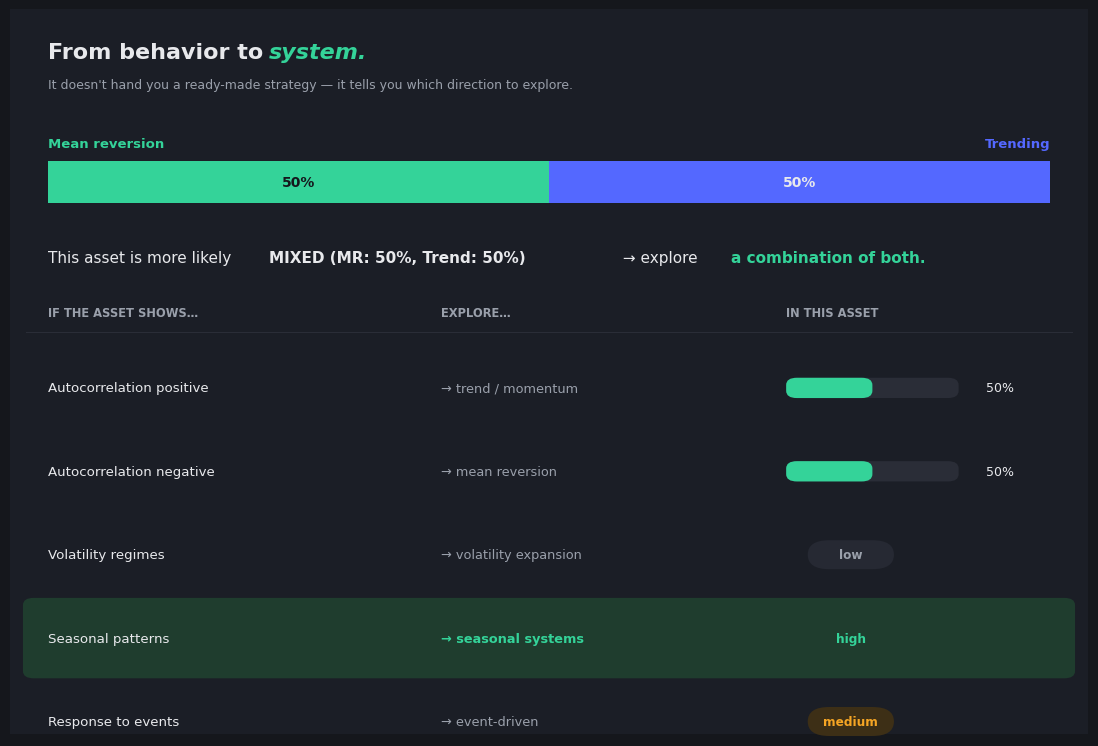


GLOSSARY
WHAT EACH NUMBER MEANS

Mean Return
How much it goes up or down on average per period. If positive, the price has an upward drift (long-term trend).
→ 0.00%

Annualized Volatility
How much the price swings, annualized. Used to compare risk across different assets.
→ 15.4%

Skewness
Which side the surprises lean toward. Positive means up moves are more violent than down moves.
→ 0.11 (right tail)

Excess Kurtosis
How frequent extreme events are. High = more shocks than a normal distribution would predict.
→ 49.53 (fat tails)

Normality (Jarque-Bera)
Test if returns follow a normal distribution. In markets, they almost never do.
→ NOT normal

Autocorrelation
Whether today's return resembles yesterday's. Negative means reversal (mean reversion).
→ Lag 1: -0.009

Hurst Exponent
Measures price memory. <0.5 = reverting.
→ 0.499

Volatility Clustering
Calm and turmoil come in waves: a volatile day tends to be followed by another volatile day (ARCH effect).
→ low

Seasonality
Whether

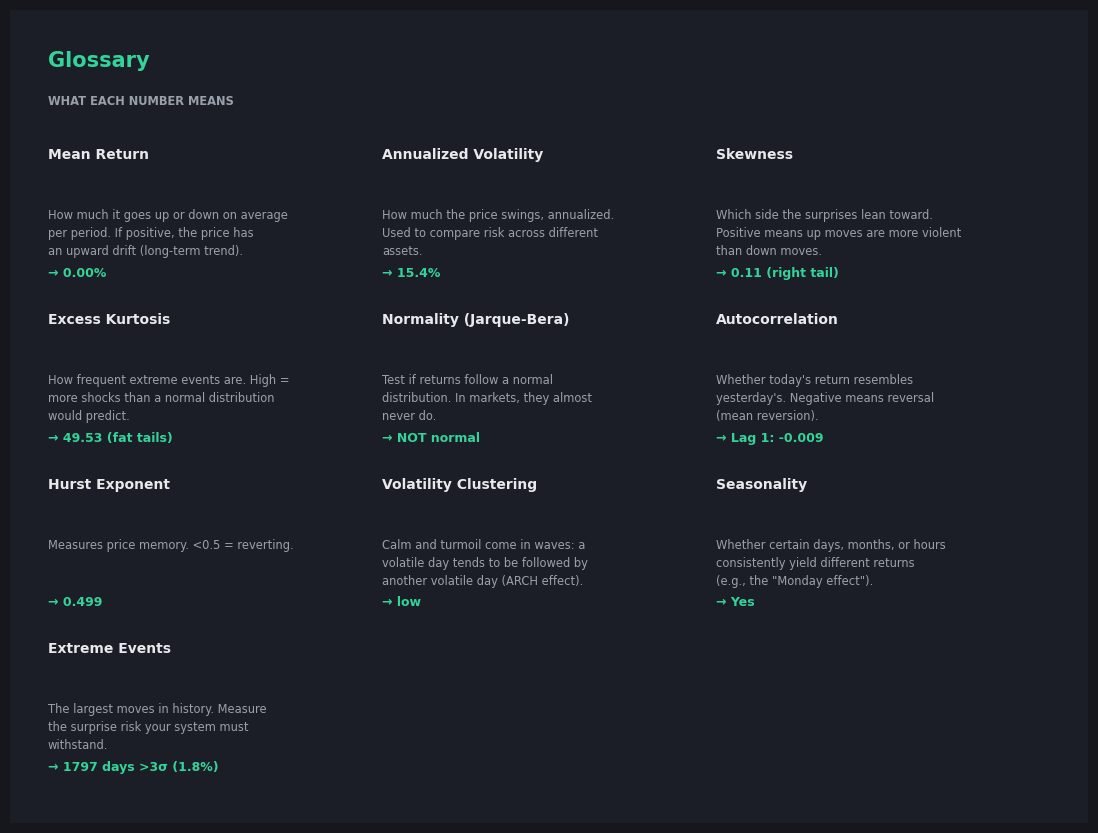




ANALYZING 4H TIMEFRAME

COMPLETE ANALYSIS: 4H
Bars: 27001
Period: 2009-09-27 16:00:00 → 2026-08-21 16:00:00

SHORT-TERM BEHAVIOR          LONG-TERM DRIFT (TREND)
RANDOM WALK
Hurst 0.49
BULLISH
~12.6%/year (mean return)

DISTRIBUTION
TAILS?
Mean return: 0.01%
Annualized volatility: 15.4%
Skewness: 0.12 (right tail)
Excess Kurtosis: 33.79 (fat tails)
Normality: NOT normal
Extreme days (>3σ): 471 (1.7%)


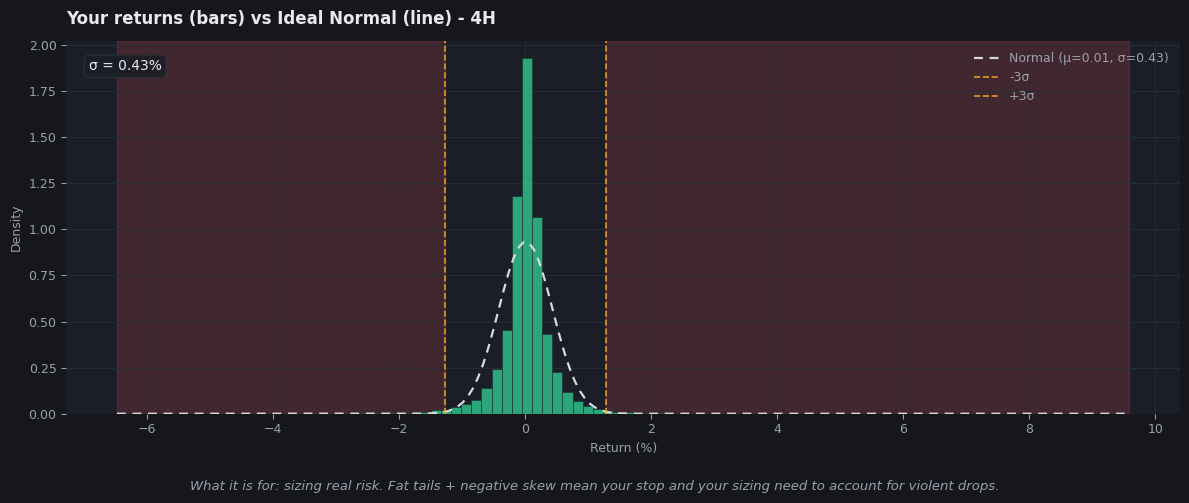


VOLATILITY
REGIMES?
Recent vs Mean vol: 0.43x
Recent volatility (daily): 0.18%
Historical volatility (daily): 0.43%
Comes in waves? low


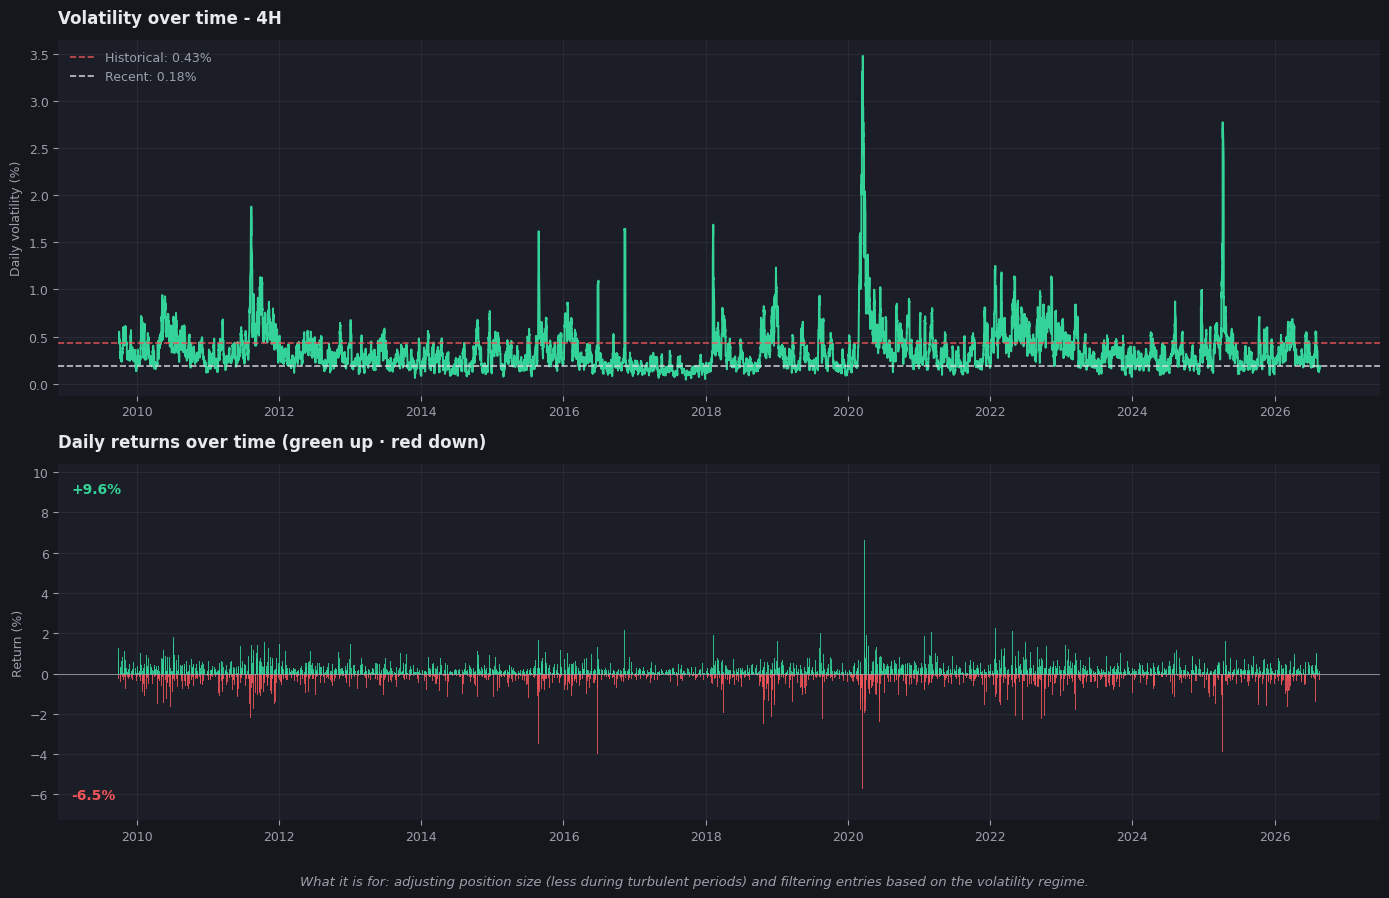


AUTOCORRELATION · MEMORY
PERSISTENCE?
Lag 1 · vs yesterday: -0.01 reverts
Lag 5 · vs 5 days ago: -0.01 reverts
Lag 20 · vs 20 days ago: 0.01 ~0


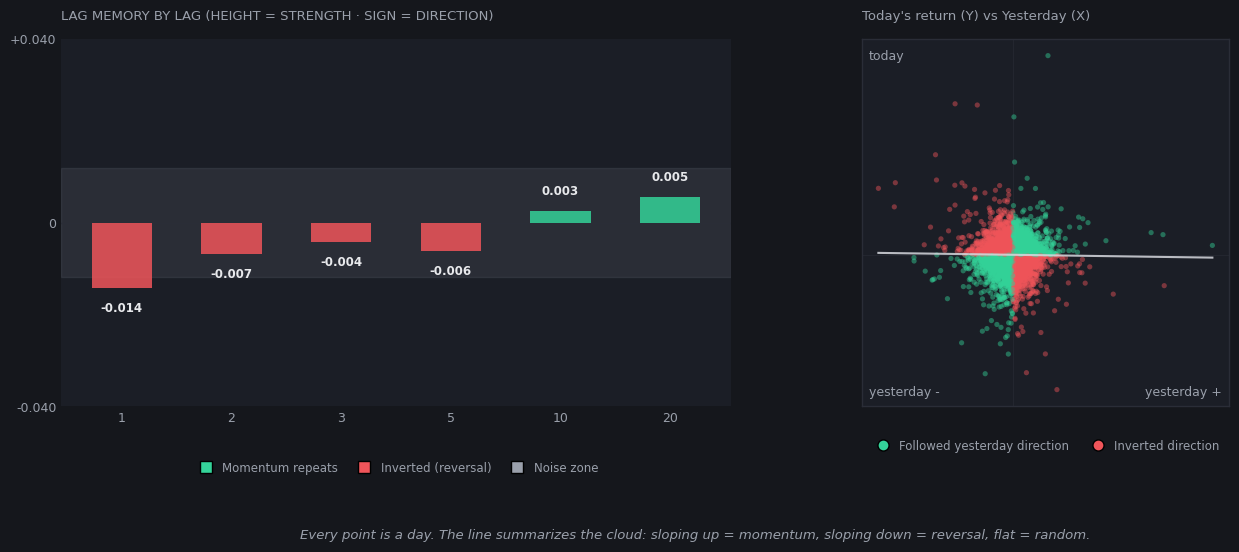


PATTERNS
SEASONALITY?


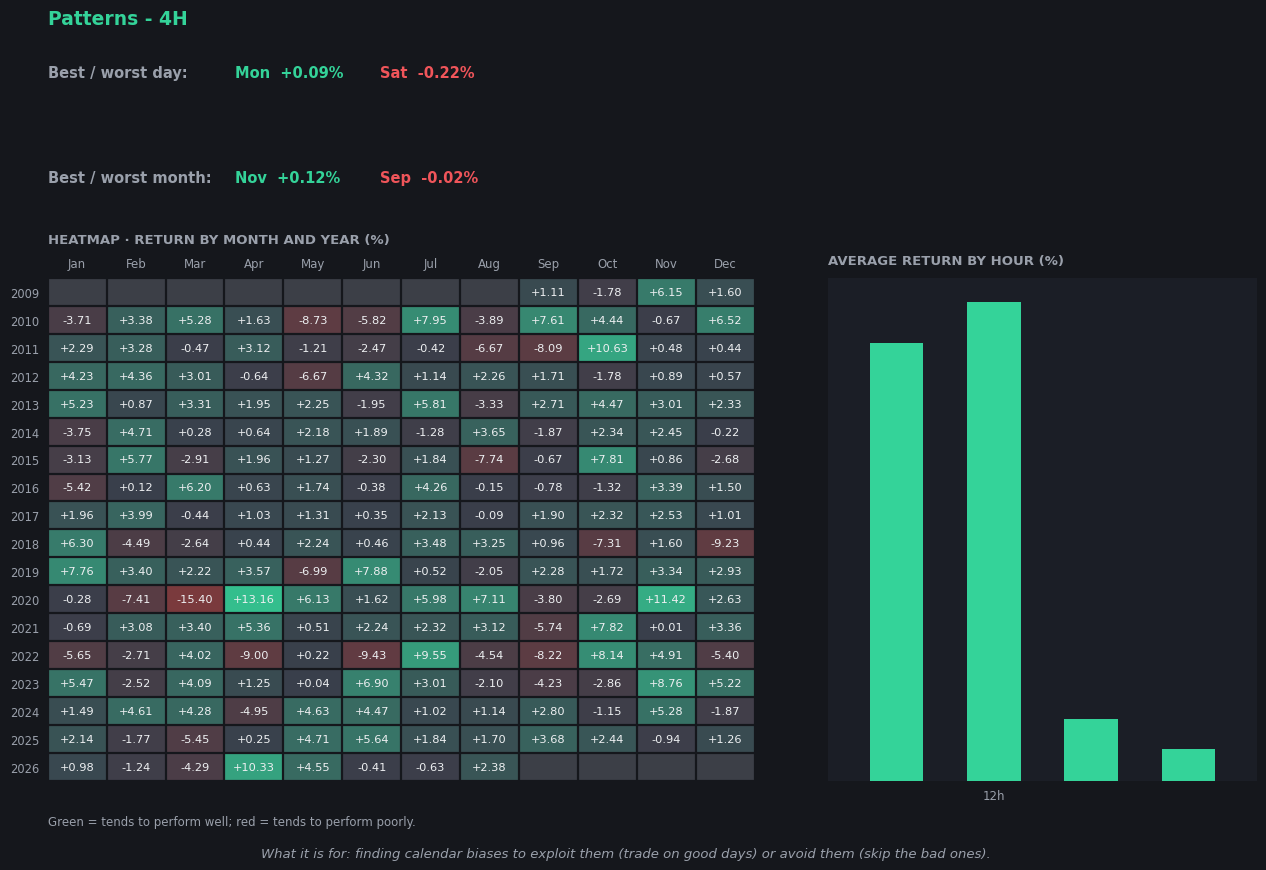


Average return by day of week (Mon-Fri, %):
Mon: 0.09%
Tue: 0.06%
Wed: 0.05%
Thu: 0.02%
Fri: 0.03%

Average return by month (%):
Jan: 0.03%
Feb: 0.04%
Mar: 0.01%
Apr: 0.07%
May: 0.02%
Jun: 0.03%
Jul: 0.11%
Aug: -0.01%
Sep: -0.02%
Oct: 0.07%
Nov: 0.12%
Dec: 0.02%

Average return by hour (6:00-22:00, %):
08:00: 0.01%
12:00: 0.01%
16:00: 0.00%
20:00: 0.00%

EXTREME EVENTS
REACTION?


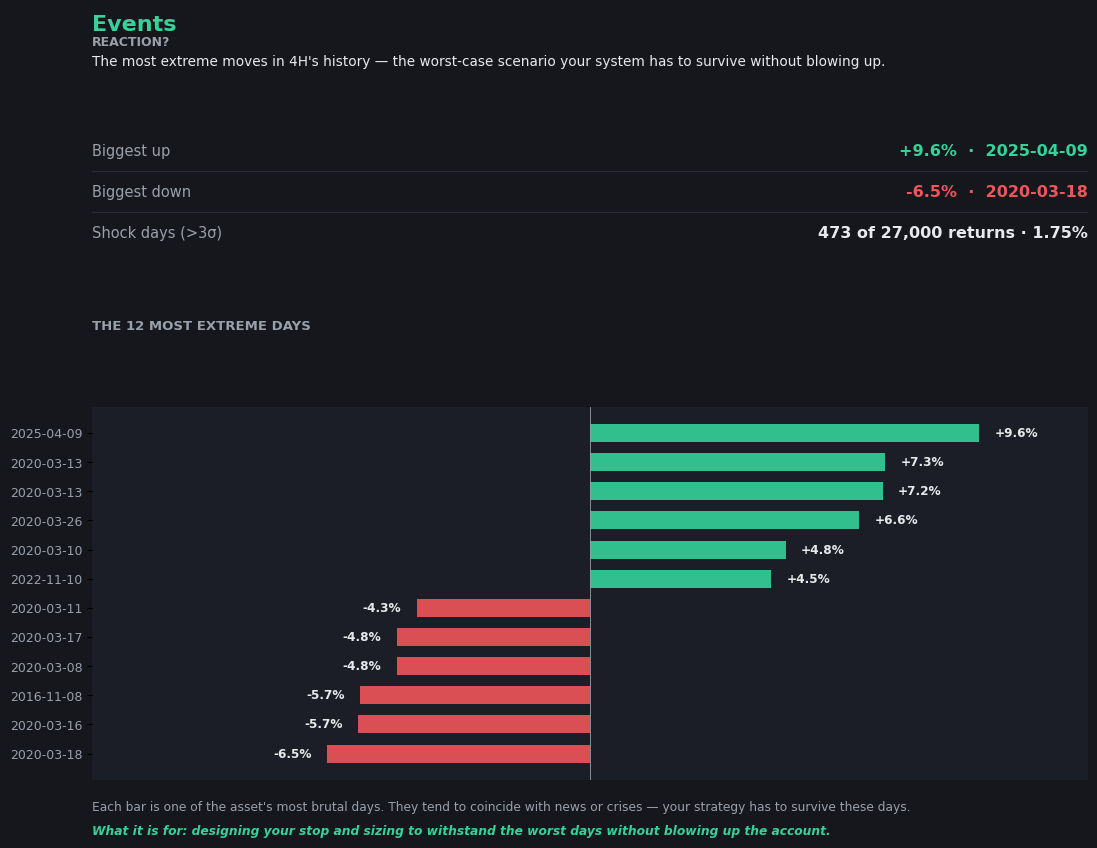

Biggest up: +9.6%
Biggest down: -6.5%
Shock days (>3σ): 471 of 27,000 returns · 1.74%

Top 12 up days:
+9.6% - 2025-04-09
+7.3% - 2020-03-13
+7.2% - 2020-03-13
+6.6% - 2020-03-26
+4.8% - 2020-03-10
+4.5% - 2022-11-10

Top 12 down days:
-6.5% - 2020-03-18
-5.7% - 2020-03-16
-5.7% - 2016-11-08
-4.8% - 2020-03-08
-4.8% - 2020-03-17
-4.3% - 2020-03-11

FROM BEHAVIOR TO SYSTEM
Mean reversion: 57%
Trending: 42%

This asset is more likely MEAN REVERSION → explore fade / reversal.

--------------------------------------------------
If the asset shows...	Explore...	In this asset
--------------------------------------------------
Autocorrelation neutral	→ mean reversion	~0%
Volatility regimes	→ volatility expansion	low
Seasonal patterns	→ seasonal systems	high
Response to events	→ event-driven	medium


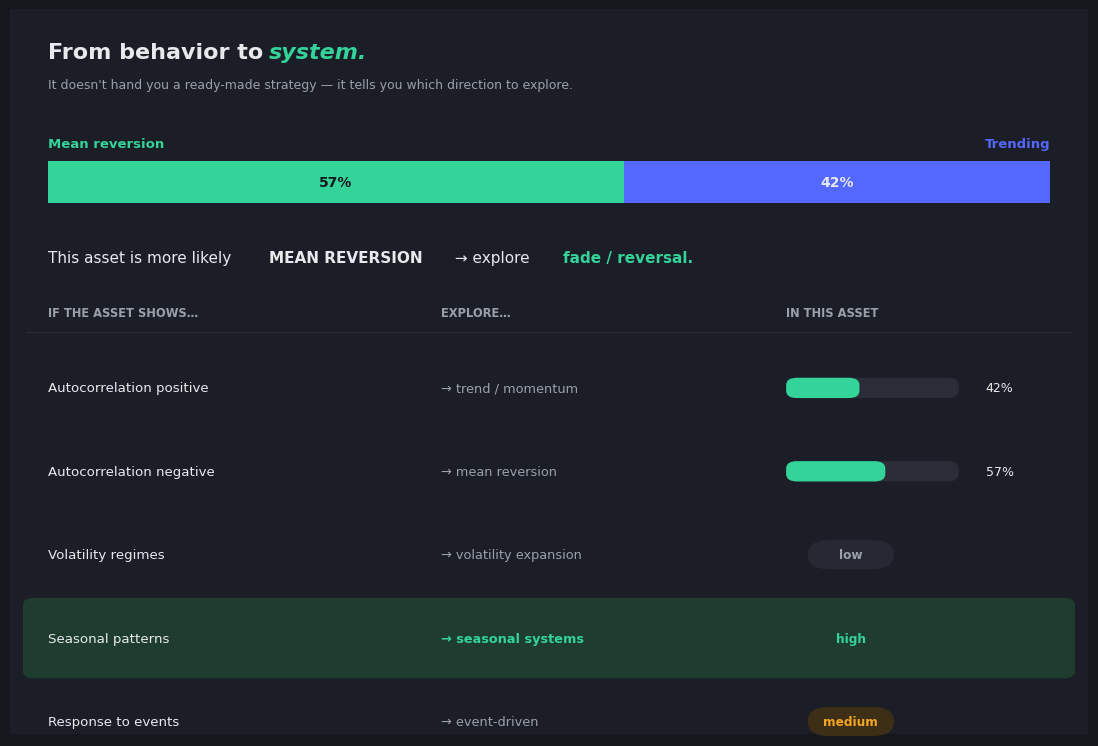


GLOSSARY
WHAT EACH NUMBER MEANS

Mean Return
How much it goes up or down on average per period. If positive, the price has an upward drift (long-term trend).
→ 0.01%

Annualized Volatility
How much the price swings, annualized. Used to compare risk across different assets.
→ 15.4%

Skewness
Which side the surprises lean toward. Positive means up moves are more violent than down moves.
→ 0.12 (right tail)

Excess Kurtosis
How frequent extreme events are. High = more shocks than a normal distribution would predict.
→ 33.79 (fat tails)

Normality (Jarque-Bera)
Test if returns follow a normal distribution. In markets, they almost never do.
→ NOT normal

Autocorrelation
Whether today's return resembles yesterday's. Negative means reversal (mean reversion).
→ Lag 1: -0.014

Hurst Exponent
Measures price memory. <0.5 = reverting.
→ 0.487

Volatility Clustering
Calm and turmoil come in waves: a volatile day tends to be followed by another volatile day (ARCH effect).
→ low

Seasonality
Whether

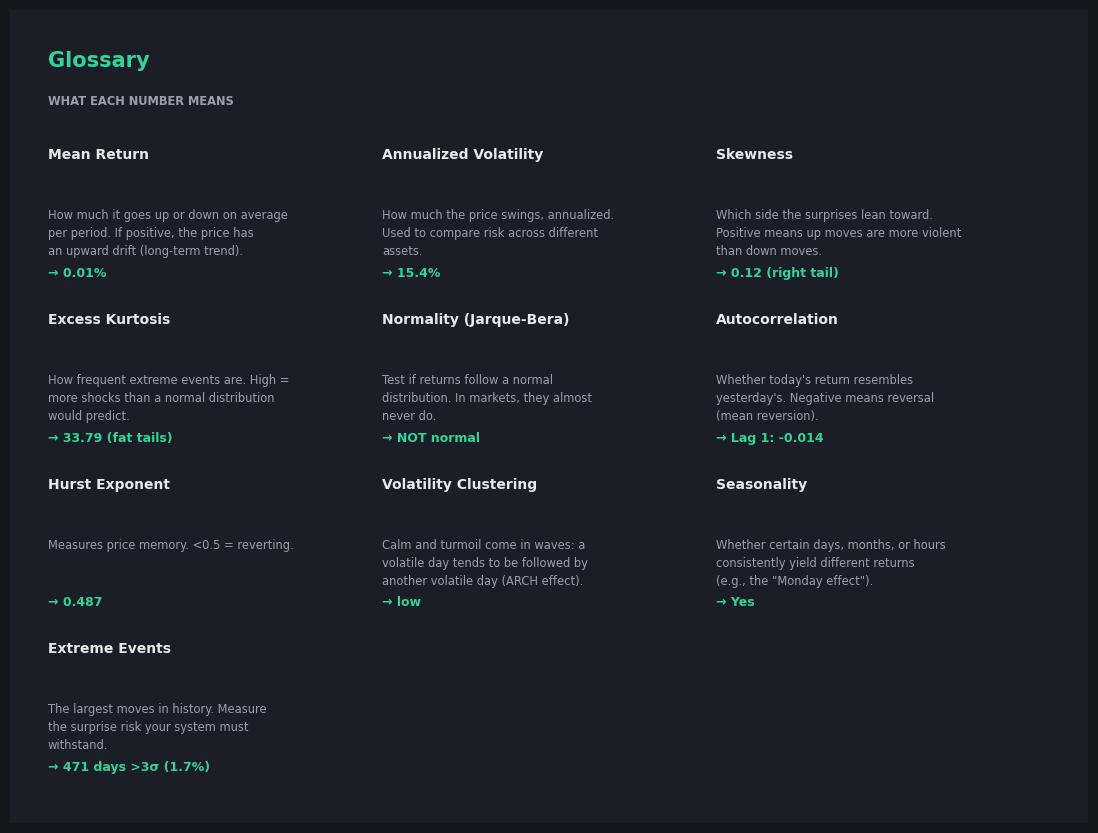




ANALYZING 1D TIMEFRAME

COMPLETE ANALYSIS: 1D
Bars: 5258
Period: 2009-09-27 00:00:00 → 2026-08-21 00:00:00

SHORT-TERM BEHAVIOR          LONG-TERM DRIFT (TREND)
RANDOM WALK
Hurst 0.47
BULLISH
~12.6%/year (mean return)

DISTRIBUTION
TAILS?
Mean return: 0.04%
Annualized volatility: 15.4%
Skewness: 0.06 (symmetric)
Excess Kurtosis: 13.23 (fat tails)
Normality: NOT normal
Extreme days (>3σ): 77 (1.5%)


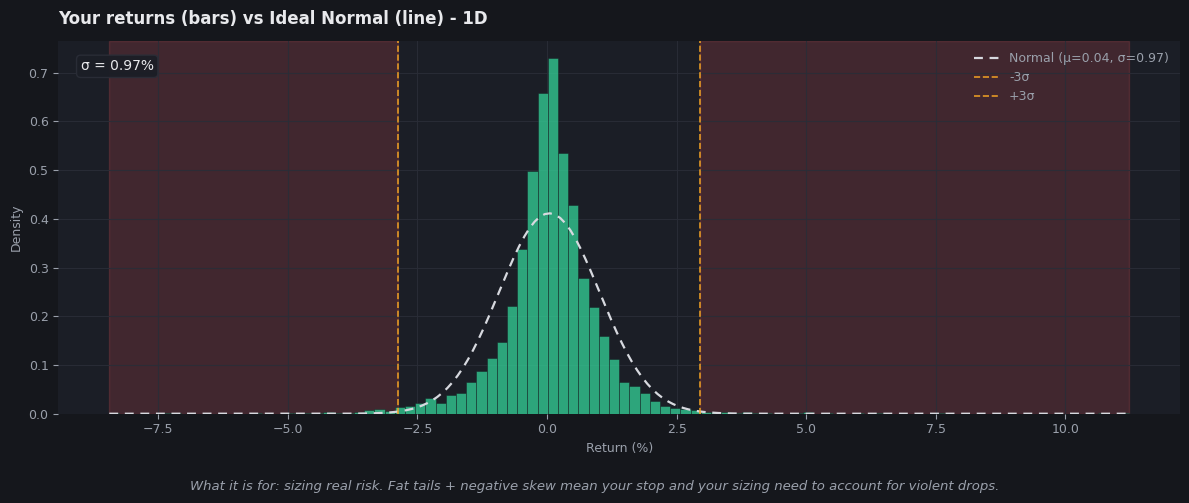


VOLATILITY
REGIMES?
Recent vs Mean vol: 0.72x
Recent volatility (daily): 0.70%
Historical volatility (daily): 0.97%
Comes in waves? strong


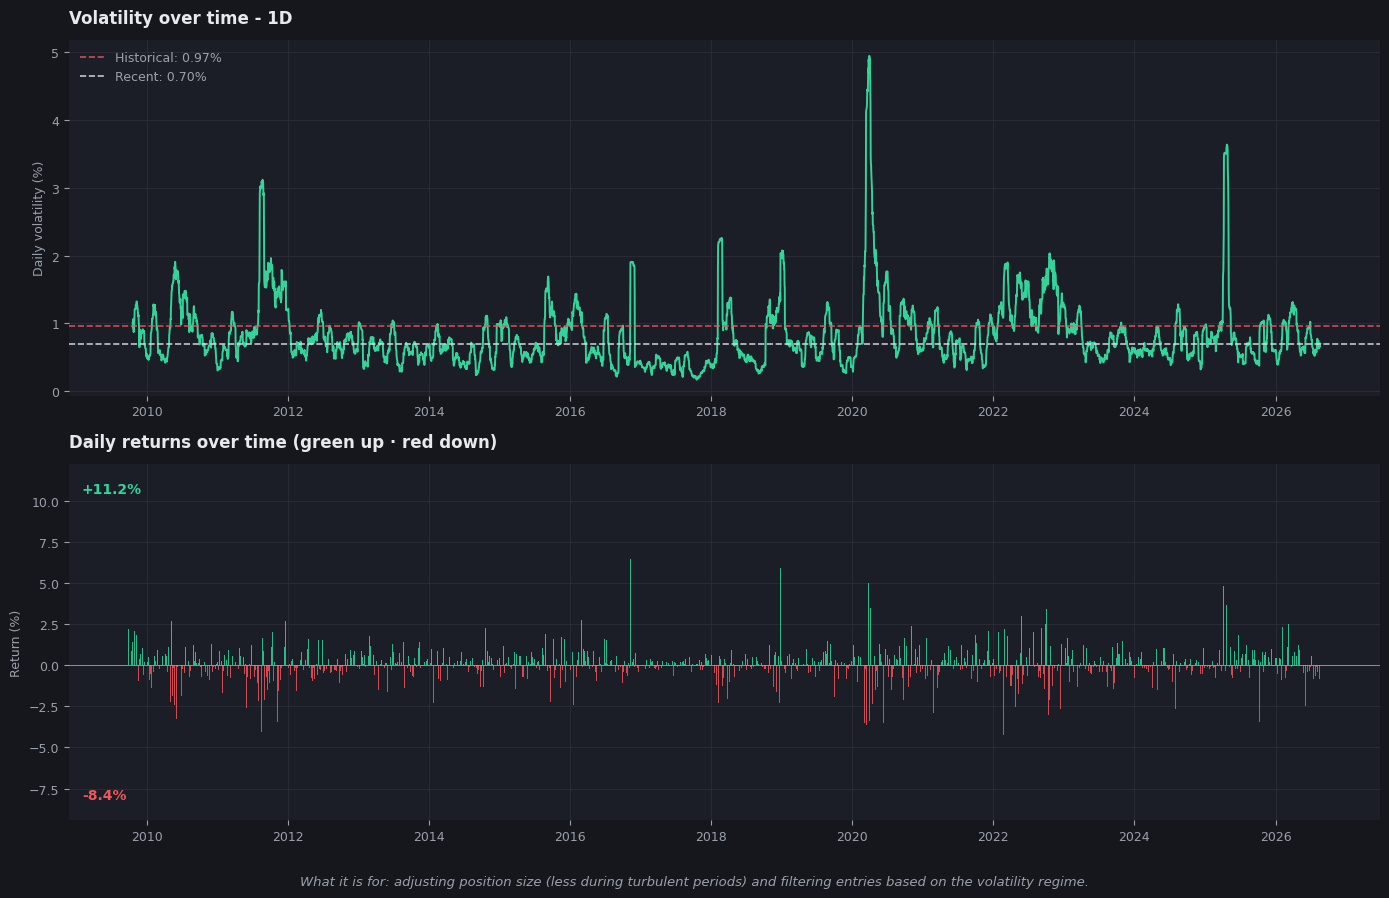


AUTOCORRELATION · MEMORY
PERSISTENCE?
Lag 1 · vs yesterday: -0.07 reverts
Lag 5 · vs 5 days ago: -0.01 reverts
Lag 20 · vs 20 days ago: 0.00 ~0


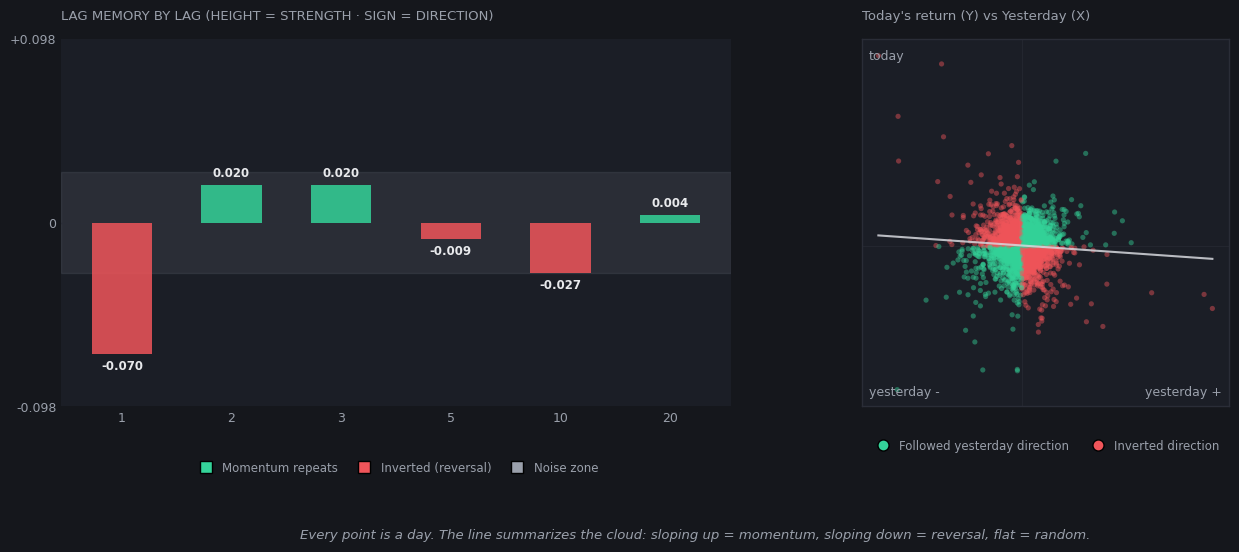


PATTERNS
SEASONALITY?


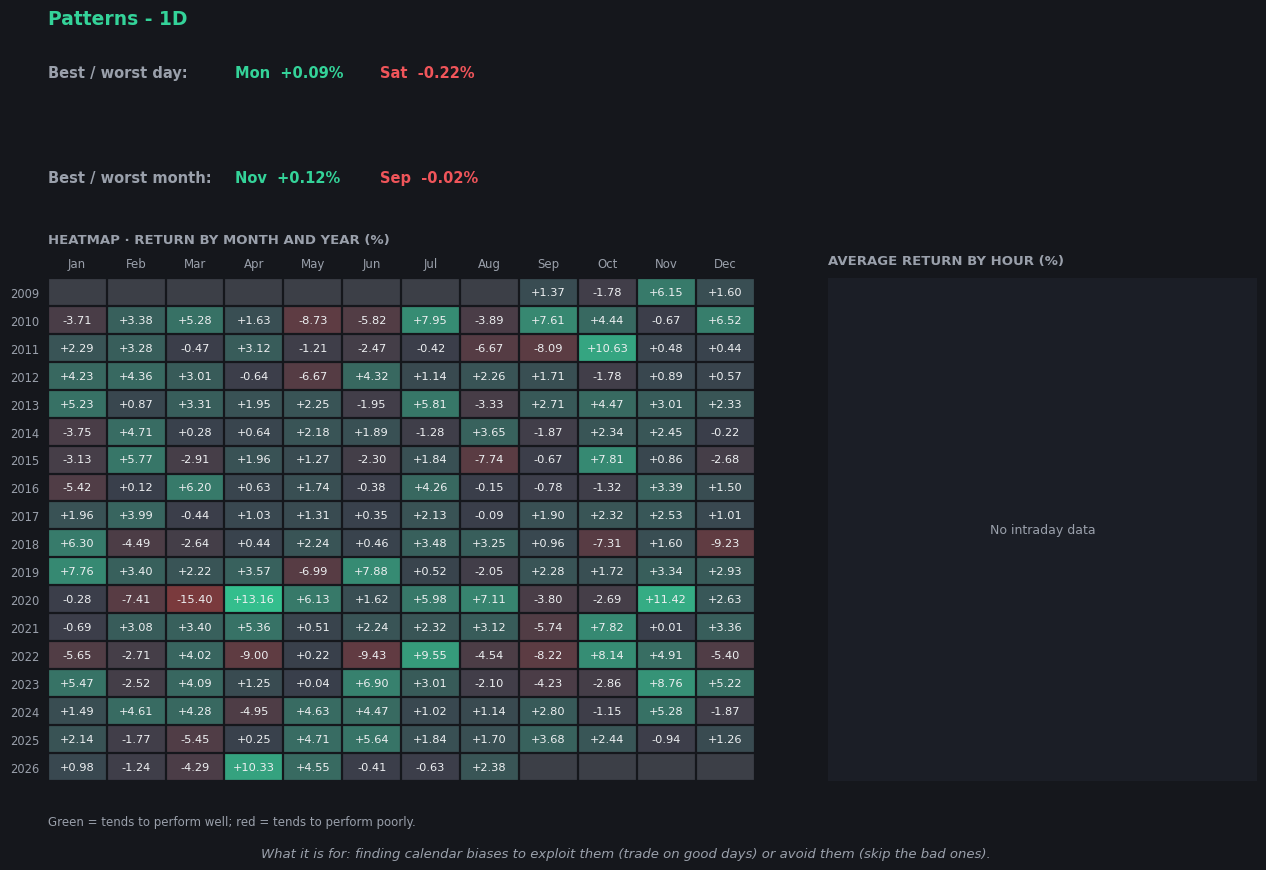


Average return by day of week (Mon-Fri, %):
Mon: 0.09%
Tue: 0.06%
Wed: 0.05%
Thu: 0.02%
Fri: 0.03%

Average return by month (%):
Jan: 0.03%
Feb: 0.04%
Mar: 0.01%
Apr: 0.07%
May: 0.02%
Jun: 0.03%
Jul: 0.11%
Aug: -0.01%
Sep: -0.02%
Oct: 0.07%
Nov: 0.12%
Dec: 0.02%

EXTREME EVENTS
REACTION?


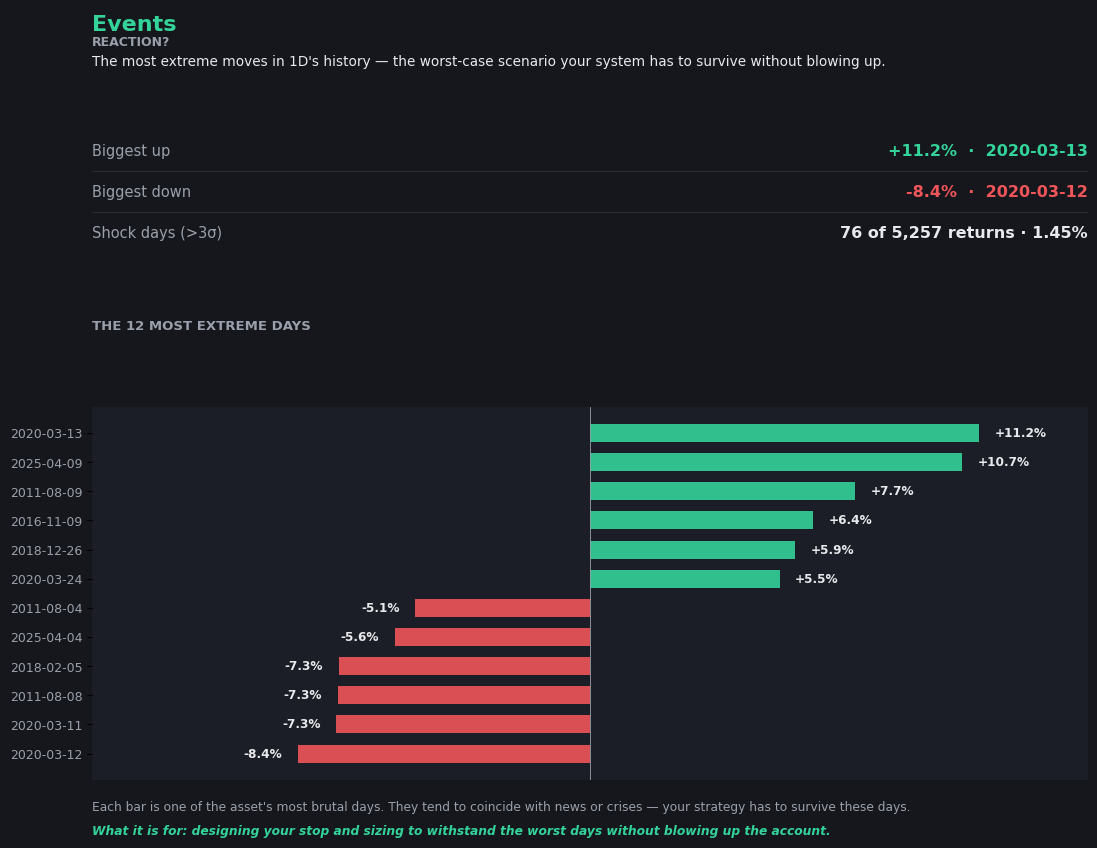

Biggest up: +11.2%
Biggest down: -8.4%
Shock days (>3σ): 77 of 5,257 returns · 1.46%

Top 12 up days:
+11.2% - 2020-03-13
+10.7% - 2025-04-09
+7.7% - 2011-08-09
+6.4% - 2016-11-09
+5.9% - 2018-12-26
+5.5% - 2020-03-24

Top 12 down days:
-8.4% - 2020-03-12
-7.3% - 2020-03-11
-7.3% - 2011-08-08
-7.3% - 2018-02-05
-5.6% - 2025-04-04
-5.1% - 2011-08-04

FROM BEHAVIOR TO SYSTEM
Mean reversion: 57%
Trending: 42%

This asset is more likely MEAN REVERSION → explore fade / reversal.

--------------------------------------------------
If the asset shows...	Explore...	In this asset
--------------------------------------------------
Autocorrelation negative	→ mean reversion	57%
Volatility regimes	→ volatility expansion	high
Seasonal patterns	→ seasonal systems	high
Response to events	→ event-driven	medium


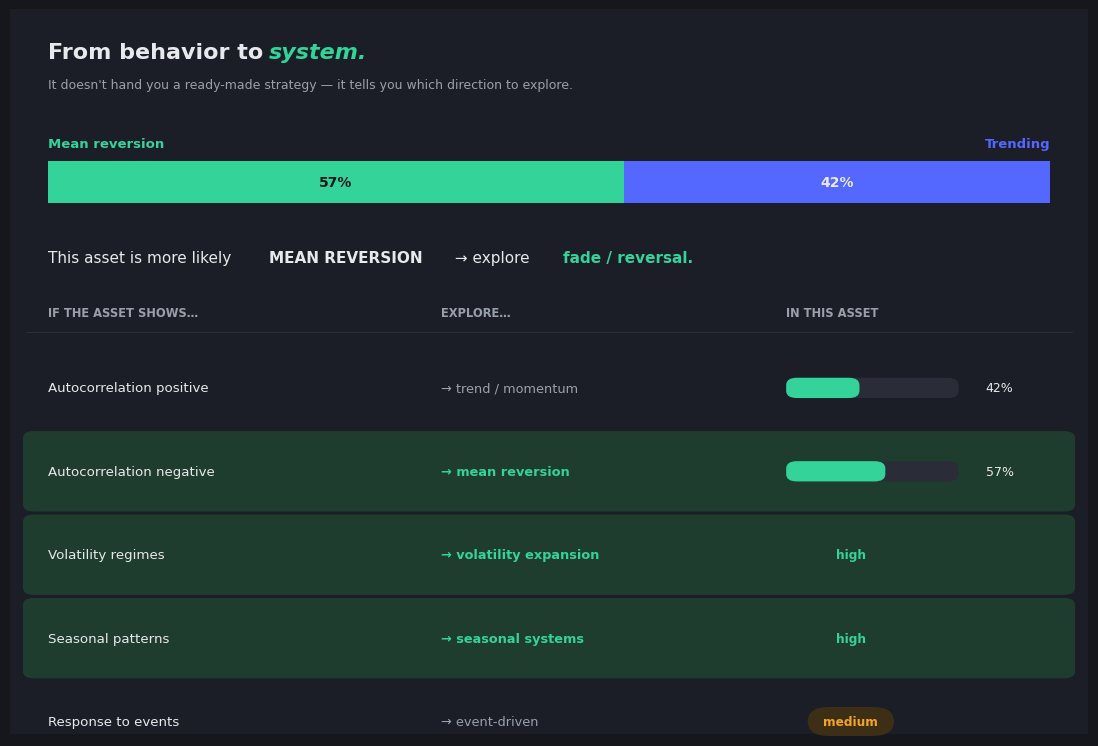


GLOSSARY
WHAT EACH NUMBER MEANS

Mean Return
How much it goes up or down on average per period. If positive, the price has an upward drift (long-term trend).
→ 0.04%

Annualized Volatility
How much the price swings, annualized. Used to compare risk across different assets.
→ 15.4%

Skewness
Which side the surprises lean toward. Positive means up moves are more violent than down moves.
→ 0.06 (symmetric)

Excess Kurtosis
How frequent extreme events are. High = more shocks than a normal distribution would predict.
→ 13.23 (fat tails)

Normality (Jarque-Bera)
Test if returns follow a normal distribution. In markets, they almost never do.
→ NOT normal

Autocorrelation
Whether today's return resembles yesterday's. Negative means reversal (mean reversion).
→ Lag 1: -0.070

Hurst Exponent
Measures price memory. <0.5 = reverting.
→ 0.470

Volatility Clustering
Calm and turmoil come in waves: a volatile day tends to be followed by another volatile day (ARCH effect).
→ strong

Seasonality
Wheth

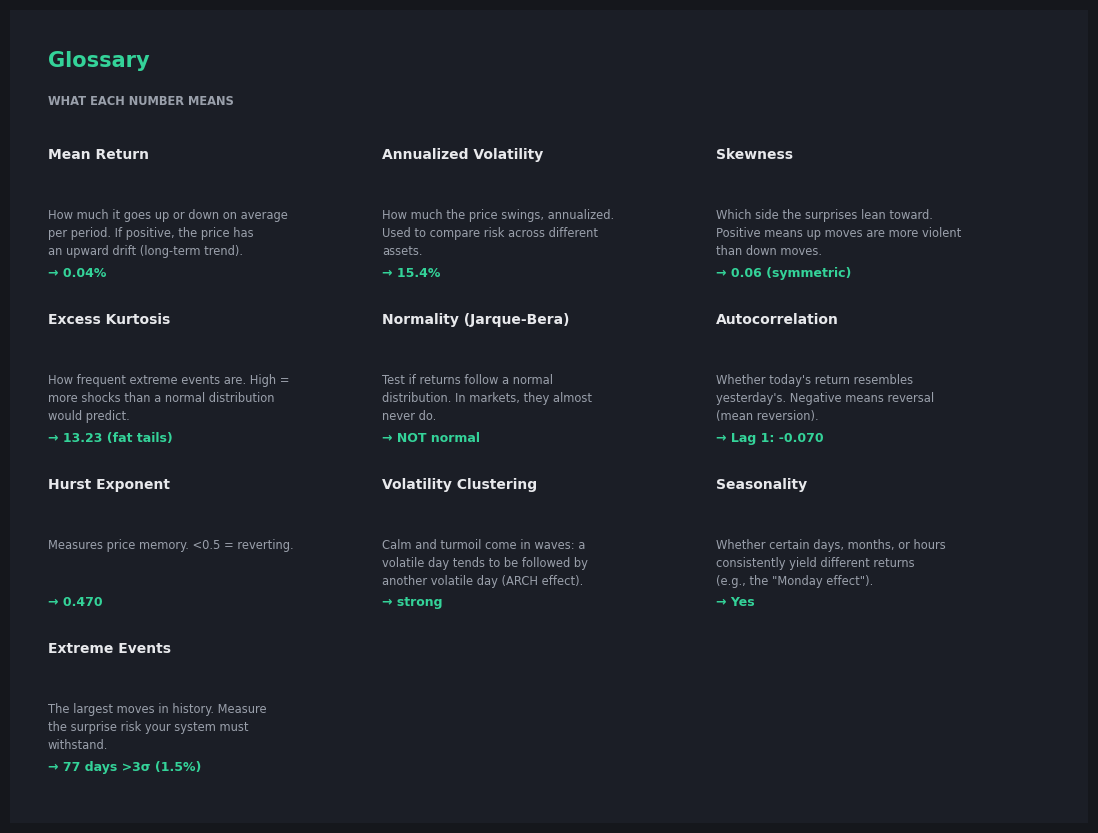




All timeframes analyzed successfully!


In [18]:
# Analyze 15min (raw data)
print("\n" + "="*70)
print("ANALYZING 15MIN TIMEFRAME")
print("="*70)
results_15min = analyze_timeframe_detailed(timeframes['15min'], '15min')

# Analyze 1H
print("\n" + "="*70)
print("ANALYZING 1H TIMEFRAME")
print("="*70)
results_1h = analyze_timeframe_detailed(timeframes['1H'], '1H')

# Analyze 4H
print("\n" + "="*70)
print("ANALYZING 4H TIMEFRAME")
print("="*70)
results_4h = analyze_timeframe_detailed(timeframes['4H'], '4H')

# Analyze 1D
print("\n" + "="*70)
print("ANALYZING 1D TIMEFRAME")
print("="*70)
results_1d = analyze_timeframe_detailed(timeframes['1D'], '1D')

print("\nAll timeframes analyzed successfully!")

## SUMMARY OF RESULTS

In [19]:
summary_df = pd.DataFrame([
    results_15min,
    results_1h,
    results_4h,
    results_1d
])

summary_df = summary_df.set_index('name')

print("\n" + "="*70)
print("SUMMARY OF KEY METRICS ACROSS TIMEFRAMES")
print("="*70)
print(summary_df[['mean_ret', 'vol_ann', 'skew', 'kurt', 'hurst', 'mr_pct', 'trend_pct']])

# Optional: Show full summary if you want all columns
print("\n" + "-"*70)
print("FULL SUMMARY (all metrics)")
print("-"*70)
print(summary_df)


SUMMARY OF KEY METRICS ACROSS TIMEFRAMES
       mean_ret    vol_ann      skew       kurt     hurst  mr_pct  trend_pct
name                                                                        
15min  0.000565  15.398053 -0.224486  83.746986  0.498651    50.0       50.0
1H     0.002219  15.398053  0.108478  49.527081  0.498700    50.0       50.0
4H     0.008327  15.398053  0.119237  33.794598  0.486967    57.5       42.5
1D     0.042831  15.398053  0.063809  13.226295  0.469740    57.5       42.5

----------------------------------------------------------------------
FULL SUMMARY (all metrics)
----------------------------------------------------------------------
       mean_ret    vol_ann      skew       kurt      normal  pct_extreme  \
name                                                                       
15min  0.000565  15.398053 -0.224486  83.746986  NOT normal     1.719551   
1H     0.002219  15.398053  0.108478  49.527081  NOT normal     1.776833   
4H     0.008327  15.39

# END OF ANALYSIS

In [20]:
print("\n" + "="*70)
print("ANALYSIS COMPLETE")
print("="*70)
print("All plots and statistics have been generated.")
print("The reusable functions from utils.py made this analysis concise and portable.")
print("\nSummary of key findings by timeframe:")
print("-"*50)
for idx, row in summary_df.iterrows():
    print(f"{idx}:")
    print(f"  Hurst: {row['hurst']:.3f} → {'Mean Reversion' if row['hurst'] < 0.45 else 'Trending' if row['hurst'] > 0.55 else 'Random Walk'}")
    print(f"  System bias: {row['mr_pct']:.0f}% Mean Reversion / {row['trend_pct']:.0f}% Trending")
    print(f"  Volatility (ann): {row['vol_ann']:.1f}%")
    print(f"  Extreme events (>3σ): {row['pct_extreme']:.2f}% of days")
    print("-"*50)


ANALYSIS COMPLETE
All plots and statistics have been generated.
The reusable functions from utils.py made this analysis concise and portable.

Summary of key findings by timeframe:
--------------------------------------------------
15min:
  Hurst: 0.499 → Random Walk
  System bias: 50% Mean Reversion / 50% Trending
  Volatility (ann): 15.4%
  Extreme events (>3σ): 1.72% of days
--------------------------------------------------
1H:
  Hurst: 0.499 → Random Walk
  System bias: 50% Mean Reversion / 50% Trending
  Volatility (ann): 15.4%
  Extreme events (>3σ): 1.78% of days
--------------------------------------------------
4H:
  Hurst: 0.487 → Random Walk
  System bias: 57% Mean Reversion / 42% Trending
  Volatility (ann): 15.4%
  Extreme events (>3σ): 1.74% of days
--------------------------------------------------
1D:
  Hurst: 0.470 → Random Walk
  System bias: 57% Mean Reversion / 42% Trending
  Volatility (ann): 15.4%
  Extreme events (>3σ): 1.46% of days
---------------------------